<a href="https://colab.research.google.com/github/fadzankerim/Network-Intrusion-Detection-System/blob/provjera_duplikata/EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# Postavke za vizualizaciju
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12
sns.set_palette('Set2')

# Prikaz svih kolona u DataFrame-u
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print('===========Biblioteke uspješno učitane===========')

===========Biblioteke uspješno učitane===========


In [2]:
#from google.colab import drive
#drive.mount('/content/drive')
#DATASET_PATH = '/content/drive/MyDrive/MPVI/Dataset/'
#DATASET_PATH = 'https://drive.google.com/drive/folders/1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm?usp=drive_link'

#Ova celija nije vise potrebna shodno implementaciji u narednoj

In [3]:
import os
import sys
from pathlib import Path

# https://drive.google.com/drive/folders/1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm?usp=drive_link
GDRIVE_FOLDER_ID = '1wqUUXHiIzMHGnOgqezpQDQyDzJ8fzXOm'
GDRIVE_FOLDER_URL = f'https://drive.google.com/drive/folders/{GDRIVE_FOLDER_ID}'

# 1. Pokušaj montiranja Google Drive-a
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except Exception as e:
    print(f'ℹ Google Drive mount preskočen ili nije na Colab-u: {e}')

def resolve_dataset_directory(folder_id=GDRIVE_FOLDER_ID):
    """
    Automatski pronalazi ili preuzima UNSW-NB15 dataset.
    Omogućava da kod radi bez greške i vlasniku i svim kolegama sa linkom!
    """
    # Poznate putanje
    candidate_paths = [
        Path('/content/Dataset'),
        Path('/content/drive/MyDrive/MPVI/Dataset'),
        Path('/content/drive/MyDrive/Dataset'),
        Path('./Dataset'),
        Path('../Dataset')
    ]

    # 1. Provjera poznatih lokacija
    for p in candidate_paths:
        if p.exists() and len(list(p.glob('**/UNSW_NB15_training-set.csv'))) > 0:
            found_file = list(p.glob('**/UNSW_NB15_training-set.csv'))[0]
            ds_root = found_file.parent.parent if found_file.parent.name == 'Training and Testing Sets' else found_file.parent
            print(f'✅ Dataset pronađen na postojećoj lokaciji: {ds_root}')
            return str(ds_root)

    # 2. Pretraga montiranog Google Drive-a ako postoji (npr. prečica kod kolege)
    drive_root = Path('/content/drive/MyDrive')
    if drive_root.exists():
        print('🔍 Pretražujem montirani Google Drive za UNSW-NB15 datasetom...')
        found = list(drive_root.glob('**/UNSW_NB15_training-set.csv'))
        if found:
            ds_root = found[0].parent.parent if found[0].parent.name == 'Training and Testing Sets' else found[0].parent
            print(f'✅ Dataset automatski detektovan na Drive-u: {ds_root}')
            return str(ds_root)

    # 3. Automatski download sa javnog Google Drive linka preko gdown
    print('📥 Dataset nije pronađen na Drive-u.')
    print('🚀 Pokrećem automatsko preuzimanje preko Google Drive linka u /content/Dataset/ ...')

    try:
        import gdown
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gdown'], check=True)
        import gdown

    download_dir = Path('/content/Dataset')
    download_dir.mkdir(parents=True, exist_ok=True)

    try:
        gdown.download_folder(id=folder_id, output=str(download_dir), quiet=False, use_cookies=False)
    except Exception as err:
        print(f'Pokušavam download preko URL-a: {err}')
        gdown.download_folder(url=GDRIVE_FOLDER_URL, output=str(download_dir), quiet=False)

    found = list(download_dir.glob('**/UNSW_NB15_training-set.csv'))
    if found:
        ds_root = found[0].parent.parent if found[0].parent.name == 'Training and Testing Sets' else found[0].parent
        print(f'✅ Dataset uspješno preuzet na: {ds_root}')
        return str(ds_root)

    return str(download_dir)

# Određivanje putanja
DATASET_PATH = resolve_dataset_directory()
if not DATASET_PATH.endswith('/'):
    DATASET_PATH += '/'

# Dinamičko mapiranje pojedinačnih fajlova (otporno na varijacije u folderima)
train_matches = list(Path(DATASET_PATH).glob('**/UNSW_NB15_training-set.csv'))
test_matches = list(Path(DATASET_PATH).glob('**/UNSW_NB15_testing-set.csv'))
features_matches = list(Path(DATASET_PATH).glob('**/NUSW-NB15_features.csv'))

TRAIN_PATH = str(train_matches[0]) if train_matches else DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_training-set.csv'
TEST_PATH = str(test_matches[0]) if test_matches else DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_testing-set.csv'
FEATURES_PATH = str(features_matches[0]) if features_matches else DATASET_PATH + 'NUSW-NB15_features.csv'

print(f' DATASET_PATH: {DATASET_PATH}')
print(f' TRAIN_PATH:   {TRAIN_PATH}')
print(f' TEST_PATH:    {TEST_PATH}')
print(f' FEATURES_PATH:{FEATURES_PATH}')


ℹ Google Drive mount preskočen ili nije na Colab-u: Error: credential propagation was unsuccessful
📥 Dataset nije pronađen na Drive-u.
🚀 Pokrećem automatsko preuzimanje preko Google Drive linka u /content/Dataset/ ...


Retrieving folder contents


Retrieving folder 1mK4_EwJ1FlQHz9aZHCGJw7vIwre9OdAk Training and Testing Sets
Processing file 1gPcayww7yxnqwoSi1FwDoHiHMaaGYWSy UNSW_NB15_testing-set.csv
Processing file 1dnfCTV1WzFqcIaQbWwox2y6LLsBC53aW UNSW_NB15_training-set.csv
Processing file 1AsooOO4-lylPHaZcEfy6O9Fe5_ZUL_VW NUSW-NB15_features.csv
Processing file 1w7Bnmm-sCCxaVfic5TcfAzzWiDNM88Yx UNSW-NB15_1.csv
Processing file 1rh1GZ8VezjJOJhvg0kIKwp7p_jXQ8IWt UNSW-NB15_2.csv
Processing file 1iGCuO1ybgCuAG7OW5Ln-U5bbM9nwXsWg UNSW-NB15_3.csv
Processing file 1cTTTYqmQ_E4GrmYydVzEpD_13-luiYw- UNSW-NB15_4.csv


Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1gPcayww7yxnqwoSi1FwDoHiHMaaGYWSy
To: /content/Dataset/Training and Testing Sets/UNSW_NB15_testing-set.csv
100%|██████████| 15.4M/15.4M [00:00<00:00, 40.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=1dnfCTV1WzFqcIaQbWwox2y6LLsBC53aW
To: /content/Dataset/Training and Testing Sets/UNSW_NB15_training-set.csv
100%|██████████| 32.3M/32.3M [00:00<00:00, 52.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1AsooOO4-lylPHaZcEfy6O9Fe5_ZUL_VW
To: /content/Dataset/NUSW-NB15_features.csv
100%|██████████| 4.04k/4.04k [00:00<00:00, 11.7MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1w7Bnmm-sCCxaVfic5TcfAzzWiDNM88Yx
From (redirected): https://drive.google.com/uc?id=1w7Bnmm-sCCxaVfic5TcfAzzWiDNM88Yx&confirm=t&uuid=d7a517b2-a4ac-4e53-9eb7-a9b4015d1b83
To: /content/Dataset/UNSW-NB15_1.csv
100%|██████████| 

✅ Dataset uspješno preuzet na: /content/Dataset
 DATASET_PATH: /content/Dataset/
 TRAIN_PATH:   /content/Dataset/Training and Testing Sets/UNSW_NB15_training-set.csv
 TEST_PATH:    /content/Dataset/Training and Testing Sets/UNSW_NB15_testing-set.csv
 FEATURES_PATH:/content/Dataset/NUSW-NB15_features.csv



Download completed


In [4]:
# Učitavanje training i testing seta
TRAIN_PATH = DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_training-set.csv'
TEST_PATH  = DATASET_PATH + 'Training and Testing Sets/UNSW_NB15_testing-set.csv'

df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

print(f'Training set: {df_train.shape[0]:,} zapisa, {df_train.shape[1]} kolona')
print(f'Testing set:  {df_test.shape[0]:,} zapisa, {df_test.shape[1]} kolona')
print(f'Ukupno:       {df_train.shape[0] + df_test.shape[0]:,} zapisa')

Training set: 175,341 zapisa, 45 kolona
Testing set:  82,332 zapisa, 45 kolona
Ukupno:       257,673 zapisa


Primijetili smo da je training set skoro duplo veći od testing seta (175k naspram 82k). Tako su autori podijelili dataset, pa smo zadržali njihovu podjelu da bismo rezultate mogli porediti sa radovima koji koriste isti dataset. Train i test smo spojili u jedan DataFrame **samo za potrebe EDA**. Kod treniranja ostaju odvojeni, a validacioni skup ćemo izdvojiti iz training seta.

In [5]:
# Kombinovanje za potpunu analizu
df_train['source'] = 'train'
df_test['source']  = 'test'
df = pd.concat([df_train, df_test], axis=0, ignore_index=True)

print(f'Kombinovani dataset: {df.shape[0]:,} zapisa, {df.shape[1]} kolona')

Kombinovani dataset: 257,673 zapisa, 46 kolona


In [6]:
# Učitavanje opisa feature-a
features_df = pd.read_csv(DATASET_PATH + 'NUSW-NB15_features.csv', encoding='latin1')
print('Feature-i dataseta:')
display(features_df)

Feature-i dataseta:


,No.,Name,Type,Description
0,1,srcip,nominal,Source IP address
1,2,sport,integer,Source port number
2,3,dstip,nominal,Destination IP address
3,4,dsport,integer,Destination port number
4,5,proto,nominal,Transaction protocol
5,6,state,nominal,Indicates to the state and its dependent proto...
6,7,dur,Float,Record total duration
7,8,sbytes,Integer,Source to destination transaction bytes
8,9,dbytes,Integer,Destination to source transaction bytes
9,10,sttl,Integer,Source to destination time to live value


In [7]:
#UCITAVANJE SIROVOG DATASETA SA 2.5M zapisa bez headera

"""column_names = [
    'srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'dur',
    'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss', 'service',
    'Sload', 'Dload', 'Spkts', 'Dpkts', 'swin', 'dwin', 'stcpb',
    'dtcpb', 'smeansz', 'dmeansz', 'trans_depth', 'res_bdy_len',
    'Sjit', 'Djit', 'Stime', 'Ltime', 'Sintpkt', 'Dintpkt',
    'tcprtt', 'synack', 'ackdat', 'is_sm_ips_ports', 'ct_state_ttl',
    'ct_flw_http_mthd', 'is_ftp_login', 'ct_ftp_cmd', 'ct_srv_src',
    'ct_srv_dst', 'ct_dst_ltm', 'ct_src_ltm', 'ct_src_dport_ltm',
    'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'attack_cat', 'label'
]
raw_files = [f'{DATASET_PATH}UNSW-NB15_{i}.csv' for i in range(1, 5)]
df_raw = pd.concat(
    [pd.read_csv(f, header=None, names=column_names, low_memory=False) for f in raw_files],
    ignore_index=True
)
print(f'Sirovi dataset: {df_raw.shape[0]:,} zapisa, {df_raw.shape[1]} kolona')"""

#Dataset ucitavamo ali ga ne koristimo u kasnijim celijama, trosi bezveze RAM

Sirovi dataset: 2,540,047 zapisa, 49 kolona


In [8]:
# Prvih 5 redova
print('=== Prvih 5 redova ===')
display(df.head())

=== Prvih 5 redova ===


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
0,1,0.1215,tcp,-,FIN,6,4,258,172,74.0875,252,254,14158.9424,8495.3652,0,0,24.2956,8.3750,30.1775,11.8306,255,621772692,2202533631,255,0.0000,0.0000,0.0000,43,43,0,0,1,0,1,1,1,1,0,0,0,1,1,0,Normal,0,train
1,2,0.6499,tcp,-,FIN,14,38,734,42014,78.4734,62,252,8395.1123,503571.3125,2,17,49.9150,15.4329,61.4269,1387.7783,255,1417884146,3077387971,255,0.0000,0.0000,0.0000,52,1106,0,0,43,1,1,1,1,2,0,0,0,1,6,0,Normal,0,train
2,3,1.6231,tcp,-,FIN,8,16,364,13186,14.1702,62,252,1572.2719,60929.2305,1,6,231.8756,102.7372,17179.5869,11420.9262,255,2116150707,2963114973,255,0.1119,0.0615,0.0504,46,824,0,0,7,1,2,1,1,3,0,0,0,2,6,0,Normal,0,train
3,4,1.6816,tcp,ftp,FIN,12,12,628,770,13.6771,62,252,2740.1790,3358.6221,1,3,152.8765,90.2357,259.0802,4991.7847,255,1107119177,1047442890,255,0.0000,0.0000,0.0000,52,64,0,0,1,1,2,1,1,3,1,1,0,2,1,0,Normal,0,train
4,5,0.4495,tcp,-,FIN,10,6,534,268,33.3738,254,252,8561.4990,3987.0598,2,1,47.7503,75.6596,2415.8376,115.8070,255,2436137549,1977154190,255,0.1284,0.0711,0.0572,53,45,0,0,43,1,2,2,1,40,0,0,0,2,39,0,Normal,0,train


In [9]:
# Posljednjih 5 redova
print('=== Posljednjih 5 redova ===')
display(df.tail())

=== Posljednjih 5 redova ===


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label,source
257668,82328,0.0000,udp,-,INT,2,0,104,0,200000.0051,254,0,83200000.0000,0.0000,0,0,0.0050,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,52,0,0,0,1,2,2,1,1,2,0,0,0,2,1,0,Normal,0,test
257669,82329,1.1061,tcp,-,FIN,20,8,18062,354,24.4101,254,252,124104.3984,2242.1099,7,1,55.8801,143.7000,4798.1310,190.9808,255,1072535109,3284291478,255,0.1732,0.1002,0.0730,903,44,0,0,1,1,2,1,1,1,0,0,0,3,2,0,Normal,0,test
257670,82330,0.0000,arp,-,INT,1,0,46,0,0.0000,0,0,0.0000,0.0000,0,0,60000.7200,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,46,0,0,0,1,2,1,1,1,1,0,0,0,1,1,1,Normal,0,test
257671,82331,0.0000,arp,-,INT,1,0,46,0,0.0000,0,0,0.0000,0.0000,0,0,60000.7320,0.0000,10.9545,0.0000,0,0,0,0,0.0000,0.0000,0.0000,46,0,0,0,1,2,1,1,1,1,0,0,0,1,1,1,Normal,0,test
257672,82332,0.0000,udp,-,INT,2,0,104,0,111111.1072,254,0,46222220.0000,0.0000,0,0,0.0090,0.0000,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0.0000,52,0,0,0,1,2,1,1,1,1,0,0,0,1,1,0,Normal,0,test


In [10]:
# Informacije o datasetu
print('=== Informacije o datasetu ===')
df.info()

=== Informacije o datasetu ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 257673 entries, 0 to 257672
Data columns (total 46 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   id                 257673 non-null  int64  
 1   dur                257673 non-null  float64
 2   proto              257673 non-null  object 
 3   service            257673 non-null  object 
 4   state              257673 non-null  object 
 5   spkts              257673 non-null  int64  
 6   dpkts              257673 non-null  int64  
 7   sbytes             257673 non-null  int64  
 8   dbytes             257673 non-null  int64  
 9   rate               257673 non-null  float64
 10  sttl               257673 non-null  int64  
 11  dttl               257673 non-null  int64  
 12  sload              257673 non-null  float64
 13  dload              257673 non-null  float64
 14  sloss              257673 non-null  int64  
 15  dloss              2

In [11]:
# Tipovi podataka
print('=== Tipovi podataka ===')
print(df.dtypes)
print(f'\nBroj numeričkih kolona: {df.select_dtypes(include=[np.number]).shape[1]}')
print(f'Broj kategoričkih kolona: {df.select_dtypes(include=["object"]).shape[1]}')

=== Tipovi podataka ===
id                     int64
dur                  float64
proto                 object
service               object
state                 object
spkts                  int64
dpkts                  int64
sbytes                 int64
dbytes                 int64
rate                 float64
sttl                   int64
dttl                   int64
sload                float64
dload                float64
sloss                  int64
dloss                  int64
sinpkt               float64
dinpkt               float64
sjit                 float64
djit                 float64
swin                   int64
stcpb                  int64
dtcpb                  int64
dwin                   int64
tcprtt               float64
synack               float64
ackdat               float64
smean                  int64
dmean                  int64
trans_depth            int64
response_body_len      int64
ct_srv_src             int64
ct_state_ttl           int64
ct_dst_ltm         

In [12]:
# Deskriptivna statistika numeričkih kolona
print('=== Deskriptivna statistika (numeričke kolone) ===')
display(df.describe().T)

=== Deskriptivna statistika (numeričke kolone) ===


,count,mean,std,min,25%,50%,75%,max
id,257673.0000,72811.8239,48929.9176,1.0000,32210.0000,64419.0000,110923.0000,175341.0000
dur,257673.0000,1.2467,5.9743,0.0000,0.0000,0.0043,0.6858,60.0000
spkts,257673.0000,19.7771,135.9472,1.0000,2.0000,4.0000,12.0000,10646.0000
dpkts,257673.0000,18.5147,111.9860,0.0000,0.0000,2.0000,10.0000,11018.0000
sbytes,257673.0000,8572.9518,173773.8806,24.0000,114.0000,528.0000,1362.0000,14355774.0000
dbytes,257673.0000,14387.2875,146199.2819,0.0000,0.0000,178.0000,1064.0000,14657531.0000
rate,257673.0000,91253.9124,160344.6367,0.0000,30.7893,2955.6649,125000.0003,1000000.0030
sttl,257673.0000,180.0009,102.4883,0.0000,62.0000,254.0000,254.0000,255.0000
dttl,257673.0000,84.7550,112.7621,0.0000,0.0000,29.0000,252.0000,254.0000
sload,257673.0000,70608691.2282,185731252.8418,0.0000,12318.0049,743942.3125,80000000.0000,5988000256.0000


In [13]:
# Deskriptivna statistika kategoričkih kolona
print('=== Deskriptivna statistika (kategoričke kolone) ===')
display(df.describe(include='object').T)

=== Deskriptivna statistika (kategoričke kolone) ===


,count,unique,top,freq
proto,257673,133,tcp,123041
service,257673,13,-,141321
state,257673,11,FIN,117164
attack_cat,257673,10,Normal,93000
source,257673,2,train,175341


In [14]:
# Oblik dataseta
print(f'Oblik dataseta: {df.shape}')
print(f'Ukupan broj ćelija: {df.shape[0] * df.shape[1]:,}')
print(f'Memorija: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB')

Oblik dataseta: (257673, 46)
Ukupan broj ćelija: 11,852,958
Memorija: 145.72 MB


In [15]:
# Provjera nedostajućih vrijednosti
missing = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_df = pd.DataFrame({
    'Nedostajuće': missing,
    'Procenat (%)': missing_pct
}).sort_values('Nedostajuće', ascending=False)

# Prikaz samo kolona koje imaju nedostajuće vrijednosti
missing_with_values = missing_df[missing_df['Nedostajuće'] > 0]

if len(missing_with_values) > 0:
    print(f'Kolone sa nedostajućim vrijednostima: {len(missing_with_values)}')
    display(missing_with_values)
else:
    print('✅ Nema nedostajućih vrijednosti (NaN) u datasetu.')

print(f'\nUkupno nedostajućih: {missing.sum():,} od {df.shape[0] * df.shape[1]:,} ćelija')

✅ Nema nedostajućih vrijednosti (NaN) u datasetu.

Ukupno nedostajućih: 0 od 11,852,958 ćelija


In [16]:
# Provjera praznih stringova i specijalnih vrijednosti
print('=== Provjera specijalnih vrijednosti ===')
for col in df.select_dtypes(include='object').columns:
    unique_vals = df[col].unique()
    has_dash = '-' in unique_vals
    has_empty = '' in unique_vals
    has_space = ' ' in unique_vals
    if has_dash or has_empty or has_space:
        print(f'  {col}: {"-" if has_dash else ""} {"prazan string" if has_empty else ""} {"razmak" if has_space else ""}')
        if has_dash:
            print(f'    Broj \'-\' vrijednosti: {(df[col] == "-").sum()}')

=== Provjera specijalnih vrijednosti ===
  service: -  
    Broj '-' vrijednosti: 141321


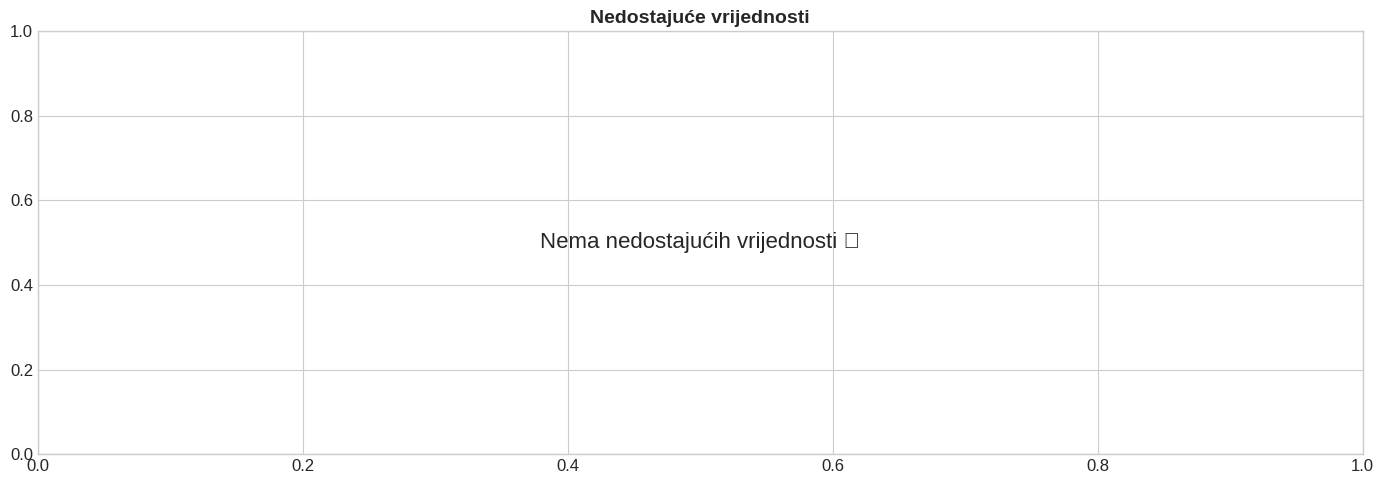

In [17]:
# Vizualizacija nedostajućih vrijednosti
fig, ax = plt.subplots(figsize=(14, 5))

null_counts = df.isnull().sum()
if null_counts.sum() > 0:
    null_counts[null_counts > 0].plot(kind='bar', ax=ax, color='coral')
    ax.set_title('Nedostajuće vrijednosti po kolonama', fontsize=14, fontweight='bold')
    ax.set_ylabel('Broj nedostajućih')
    ax.tick_params(axis='x', rotation=45)
else:
    ax.text(0.5, 0.5, 'Nema nedostajućih vrijednosti!',
            ha='center', va='center', fontsize=16, transform=ax.transAxes)
    ax.set_title('Nedostajuće vrijednosti', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

**Provjera duplikata**

=== Duplikati unutar setova (bez kolone id) ===
Training set: 67,601 duplikata (38.55%)
Testing set:  26,387 duplikata (32.05%)
=== Preklapanje train i test seta ===
Jedinstveni zapisi u test setu: 55,945
Od toga postoje i u train setu: 940 (1.68%)
=== Konfliktni zapisi (isti feature-i, različita klasa) ===
Grupe sa različitim label-om:      414
Grupe sa različitim attack_cat-om: 2,445
=== Procenat duplikata po kategoriji (training set) ===


,duplikat
attack_cat,
Generic,89.5500
DoS,68.9700
Exploits,40.5700
Reconnaissance,28.3000
Analysis,20.3000
Backdoor,12.0800
Fuzzers,11.1900
Normal,7.3400
Shellcode,3.7100


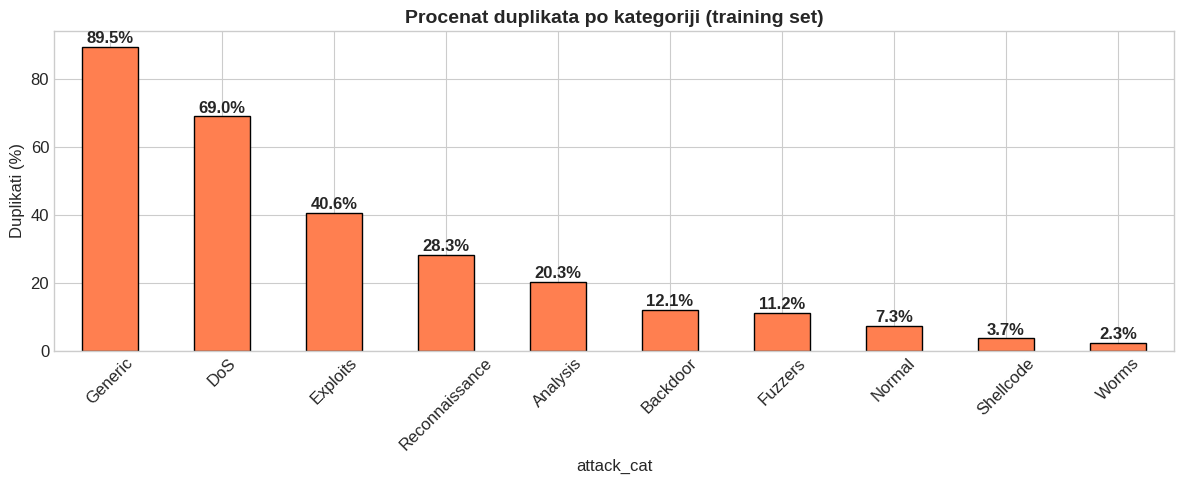

In [41]:
#Kolone za provjeru duplikata (bez id i pomoćne kolone source)
feature_cols = [c for c in df_train.columns if c not in ['id', 'source']]
# Samo ulazni feature-i (bez ciljnih varijabli)
input_cols = [c for c in feature_cols if c not in ['label', 'attack_cat']]

dup_train = df_train.duplicated(subset=feature_cols).sum()
dup_test = df_test.duplicated(subset=feature_cols).sum()

print('=== Duplikati unutar setova (bez kolone id) ===')
print(f'Training set: {dup_train:,} duplikata ({dup_train / len(df_train) * 100:.2f}%)')
print(f'Testing set:  {dup_test:,} duplikata ({dup_test / len(df_test) * 100:.2f}%)')


# Da li se isti zapisi pojavljuju i u train i u test setu?
train_unique = df_train[feature_cols].drop_duplicates()
test_unique = df_test[feature_cols].drop_duplicates()
overlap = test_unique.merge(train_unique, on=feature_cols, how='inner')

print('=== Preklapanje train i test seta ===')
print(f'Jedinstveni zapisi u test setu: {len(test_unique):,}')
print(f'Od toga postoje i u train setu: {len(overlap):,} ({len(overlap) / len(test_unique) * 100:.2f}%)')


# Isti ulazni feature-i, a različita klasa → model ih ne može razlikovati
label_conflicts = (df.groupby(input_cols)['label'].nunique() > 1).sum()
cat_conflicts = (df.groupby(input_cols)['attack_cat'].nunique() > 1).sum()

print('=== Konfliktni zapisi (isti feature-i, različita klasa) ===')
print(f'Grupe sa različitim label-om:      {label_conflicts:,}')
print(f'Grupe sa različitim attack_cat-om: {cat_conflicts:,}')


# Procenat duplikata po kategoriji napada (training set)
dup_pct = (df_train.assign(duplikat=df_train.duplicated(subset=feature_cols))
           .groupby('attack_cat')['duplikat'].mean() * 100).sort_values(ascending=False)

print('=== Procenat duplikata po kategoriji (training set) ===')
display(dup_pct.round(2))

fig, ax = plt.subplots(figsize=(12, 5))
dup_pct.plot(kind='bar', ax=ax, color='coral', edgecolor='black')
ax.set_title('Procenat duplikata po kategoriji (training set)', fontsize=14, fontweight='bold')
ax.set_ylabel('Duplikati (%)')
ax.tick_params(axis='x', rotation=45)
for i, v in enumerate(dup_pct):
    ax.text(i, v + 1, f'{v:.1f}%', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

- Dataset ima **jako puno duplikata**: 38,6% training seta i 32,1% testing seta su zapisi koji se već pojavljuju (ne računajući `id`).
- Duplikati nisu ravnomjerno raspoređeni. Kod **Generic napada čak 89,6%** zapisa su duplikati, a kod DoS-a 69%. Normal saobraćaj ima samo 7,3%. To znači da je Generic klasa "napuhana": stvarno različitih Generic zapisa ima mnogo manje nego što izgleda iz distribucije klasa.
- Ako duplikate ostavimo, model se previše prilagodi ovim ponavljanim zapisima, a metrike na validaciji izgledaju bolje nego što jesu (isti zapis završi i u train i u validacionom skupu).

Mislim da trebamo duplikate izbaciti iz training set-a

In [42]:
# Distribucija label-a (0 = Normal, 1 = Attack)
print('=== Distribucija ciljne varijable (label) ===')
label_counts = df['label'].value_counts()
label_pct = df['label'].value_counts(normalize=True) * 100

label_summary = pd.DataFrame({
    'Broj zapisa': label_counts,
    'Procenat (%)': label_pct
})
label_summary.index = ['Normal (0)' if i == 0 else 'Napad (1)' for i in label_summary.index]
display(label_summary)

print(f'\nOdnos Normal:Napad = 1:{label_counts[1]/label_counts[0]:.2f}')

=== Distribucija ciljne varijable (label) ===


,Broj zapisa,Procenat (%)
Napad (1),164673,63.9077
Normal (0),93000,36.0923



Odnos Normal:Napad = 1:1.77


- Dataset ima više napada nego normalnog saobraćaja: oko **64% napada** i 36% normalnog saobraćaja. U stvarnoj mreži je obrnuto, pa ovo treba imati na umu kad tumačimo rezultate.
- Među napadima je **nebalans jako izražen**. Generic, Exploits i Fuzzers zajedno čine većinu napada, dok **Worms ima samo 174 zapisa (0,07%)**, a Shellcode, Backdoor i Analysis su ispod 1,1%.
- Zbog toga **accuracy nije dobra metrika** za ovaj problem. Model koji nikad ne prepozna Worms i dalje može imati visok accuracy. Umjesto toga ćemo pratiti **macro F1**, **recall po klasama** i **confusion matrix**.
- Za rijetke klase  bi bilo dobro probati težine klasa u loss funkciji i/ili oversampling, pa uporediti rezultate.

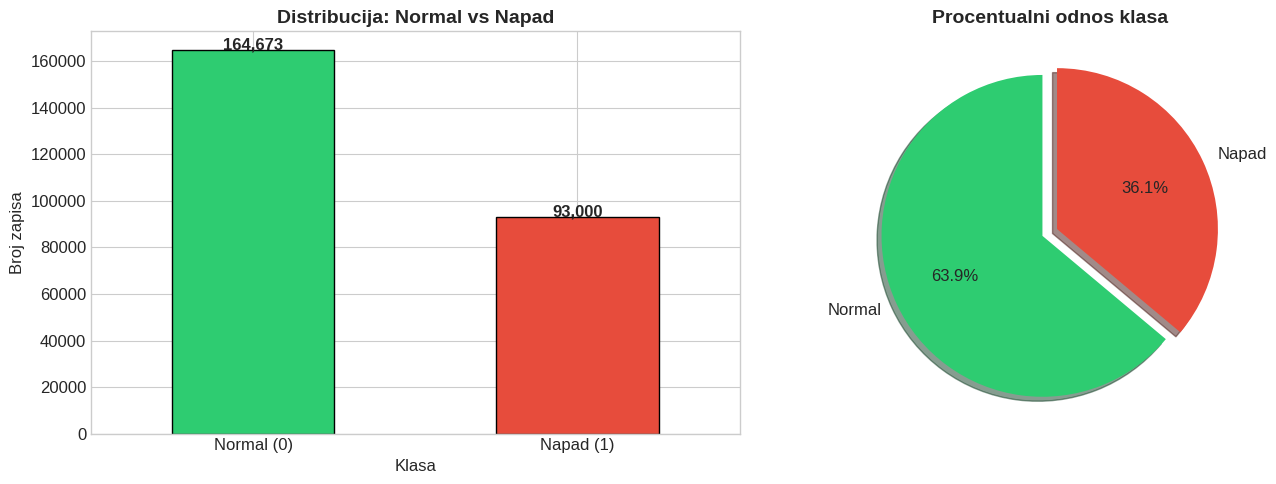

In [19]:
# Vizualizacija distribucije label-a
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart
colors = ['#2ecc71', '#e74c3c']
label_counts.plot(kind='bar', ax=axes[0], color=colors, edgecolor='black')
axes[0].set_title('Distribucija: Normal vs Napad', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Klasa')
axes[0].set_ylabel('Broj zapisa')
axes[0].set_xticklabels(['Normal (0)', 'Napad (1)'], rotation=0)
for i, v in enumerate(label_counts):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Pie chart
axes[1].pie(label_counts, labels=['Normal', 'Napad'], autopct='%1.1f%%',
            colors=colors, startangle=90, explode=(0.05, 0.05),
            shadow=True, textprops={'fontsize': 12})
axes[1].set_title('Procentualni odnos klasa', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

=== Distribucija po Train/Test setovima ===


,Normal (0),Napad (1),Ukupno
source,,,
test,37000,45332,82332
train,56000,119341,175341
Ukupno,93000,164673,257673


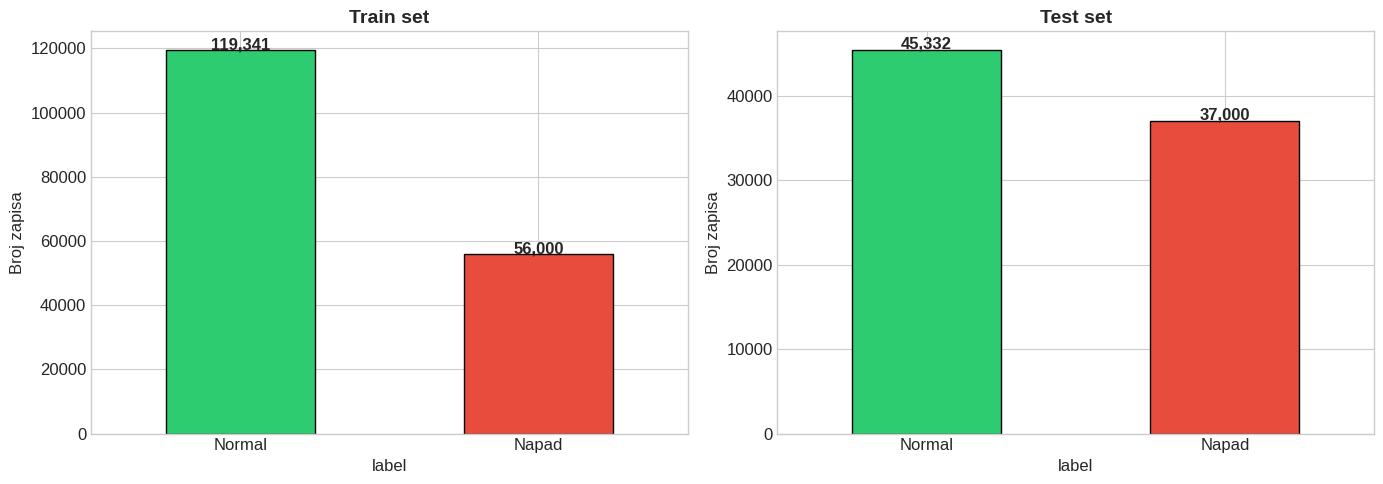

In [20]:
# Distribucija label-a po Train/Test setu
print('=== Distribucija po Train/Test setovima ===')
cross_tab = pd.crosstab(df['source'], df['label'], margins=True, margins_name='Ukupno')
cross_tab.columns = ['Normal (0)', 'Napad (1)', 'Ukupno']
display(cross_tab)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, src in enumerate(['train', 'test']):
    subset = df[df['source'] == src]['label'].value_counts()
    subset.plot(kind='bar', ax=axes[idx], color=colors, edgecolor='black')
    axes[idx].set_title(f'{src.capitalize()} set', fontsize=14, fontweight='bold')
    axes[idx].set_xticklabels(['Normal', 'Napad'], rotation=0)
    axes[idx].set_ylabel('Broj zapisa')
    for i, v in enumerate(subset):
        axes[idx].text(i, v + 200, f'{v:,}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [21]:
# Pregled kategorija napada
print('=== Kategorije napada ===')
print(f'Jedinstvene kategorije: {df["attack_cat"].nunique()}')
print(f'\nVrijednosti:')
print(df['attack_cat'].unique())

=== Kategorije napada ===
Jedinstvene kategorije: 10

Vrijednosti:
['Normal' 'Backdoor' 'Analysis' 'Fuzzers' 'Shellcode' 'Reconnaissance'
 'Exploits' 'DoS' 'Worms' 'Generic']


In [22]:
# Čišćenje attack_cat kolone (uklanjanje razmaka)
df['attack_cat'] = df['attack_cat'].str.strip()

# Distribucija kategorija napada
attack_counts = df['attack_cat'].value_counts()
attack_pct = df['attack_cat'].value_counts(normalize=True) * 100

attack_summary = pd.DataFrame({
    'Broj zapisa': attack_counts,
    'Procenat (%)': attack_pct.round(2)
})
display(attack_summary)

,Broj zapisa,Procenat (%)
attack_cat,,
Normal,93000,36.0900
Generic,58871,22.8500
Exploits,44525,17.2800
Fuzzers,24246,9.4100
DoS,16353,6.3500
Reconnaissance,13987,5.4300
Analysis,2677,1.0400
Backdoor,2329,0.9000
Shellcode,1511,0.5900


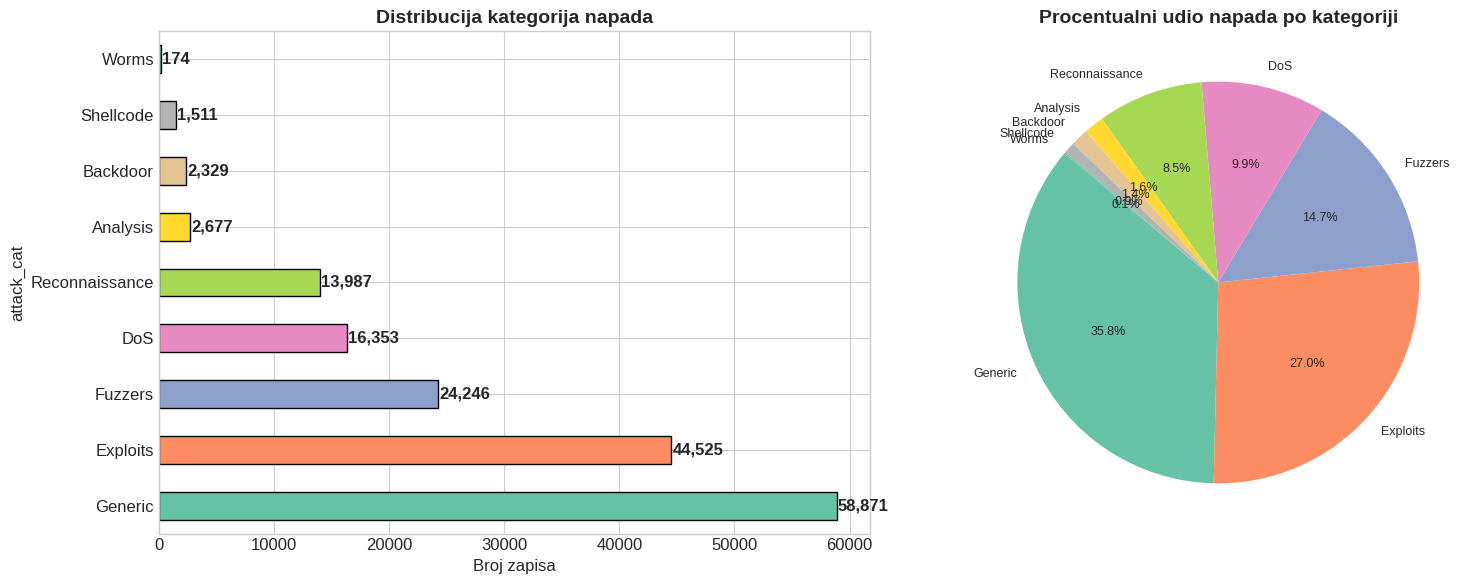

In [23]:
# Vizualizacija kategorija napada
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Bar chart – sve kategorije
attack_only = df[df['label'] == 1]['attack_cat'].value_counts()
attack_only.plot(kind='barh', ax=axes[0], color=sns.color_palette('Set2', len(attack_only)),
                 edgecolor='black')
axes[0].set_title('Distribucija kategorija napada', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Broj zapisa')
for i, v in enumerate(attack_only):
    axes[0].text(v + 100, i, f'{v:,}', va='center', fontweight='bold')

# Pie chart – procentualno
axes[1].pie(attack_only, labels=attack_only.index, autopct='%1.1f%%',
            startangle=140, textprops={'fontsize': 9})
axes[1].set_title('Procentualni udio napada po kategoriji', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

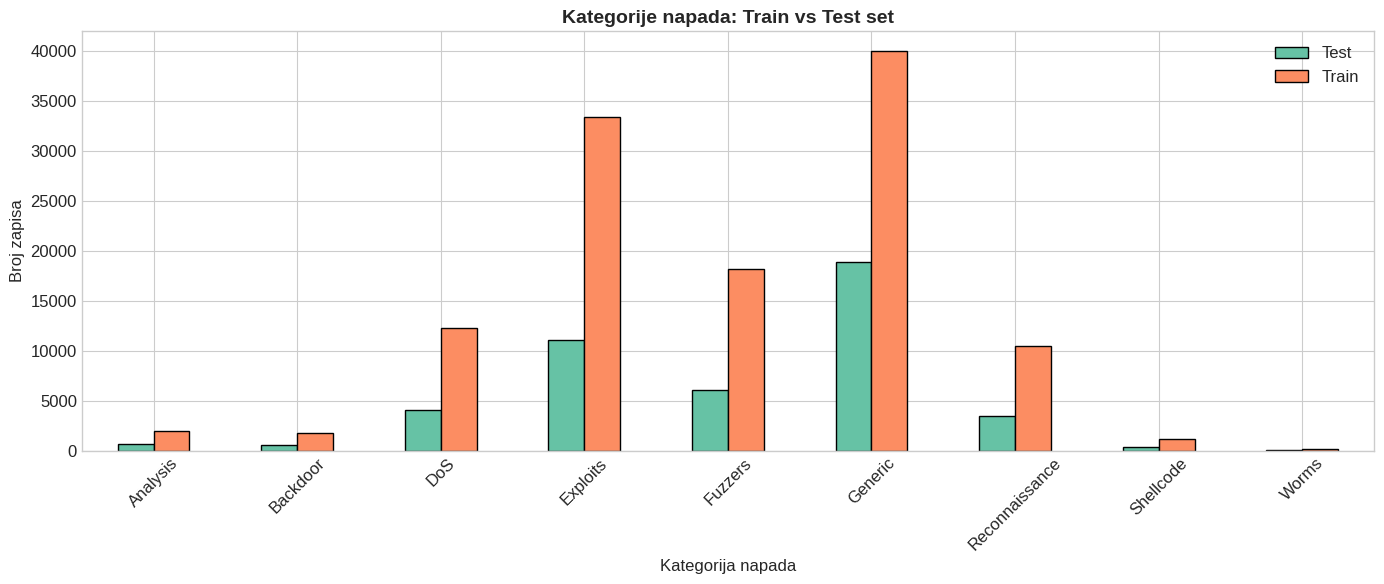

In [24]:
# Distribucija kategorija napada po Train/Test setu
fig, ax = plt.subplots(figsize=(14, 6))

attack_cross = pd.crosstab(df[df['label'] == 1]['attack_cat'], df[df['label'] == 1]['source'])
attack_cross.plot(kind='bar', ax=ax, edgecolor='black')
ax.set_title('Kategorije napada: Train vs Test set', fontsize=14, fontweight='bold')
ax.set_xlabel('Kategorija napada')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
ax.legend(['Test', 'Train'])

plt.tight_layout()
plt.show()

In [25]:
# Lista numeričkih kolona (bez id, label, source)
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
exclude_cols = ['id', 'label']
numeric_features = [c for c in numeric_cols if c not in exclude_cols]

print(f'Numerički feature-i ({len(numeric_features)}):')
print(numeric_features)

Numerički feature-i (39):
['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']


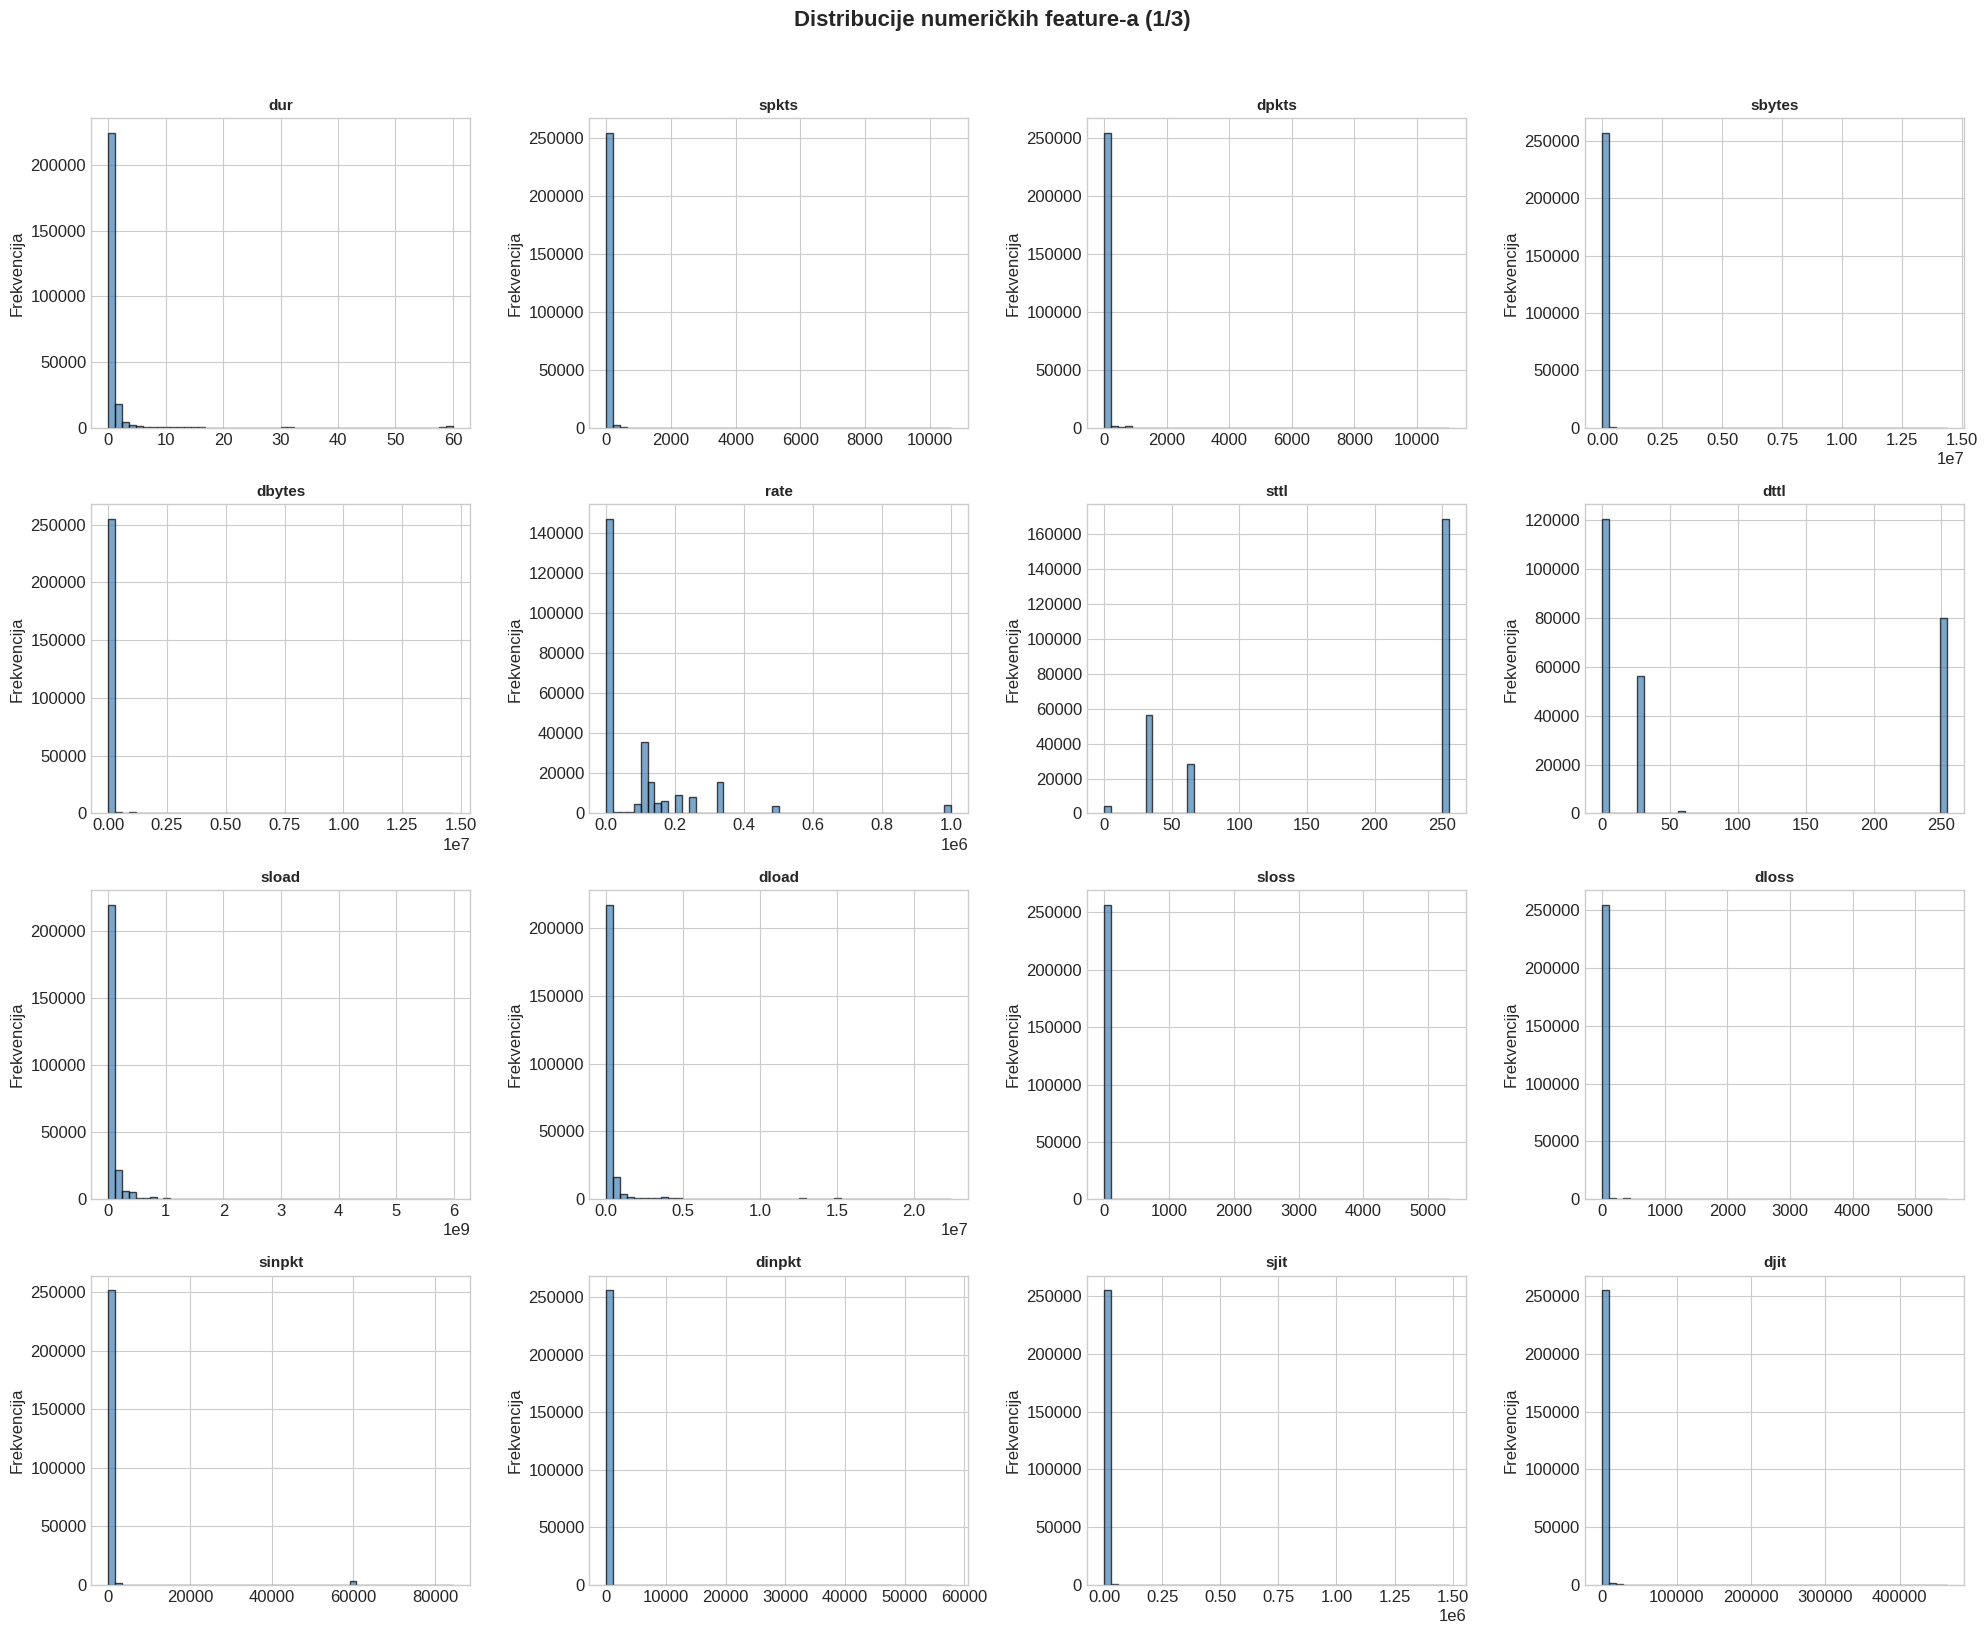

In [26]:
# Histogrami za prvih 16 numeričkih feature-a
fig, axes = plt.subplots(4, 4, figsize=(20, 16))
axes = axes.flatten()

for idx, col in enumerate(numeric_features[:16]):
    ax = axes[idx]
    df[col].hist(bins=50, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=11, fontweight='bold')
    ax.set_ylabel('Frekvencija')

plt.suptitle('Distribucije numeričkih feature-a (1/3)', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

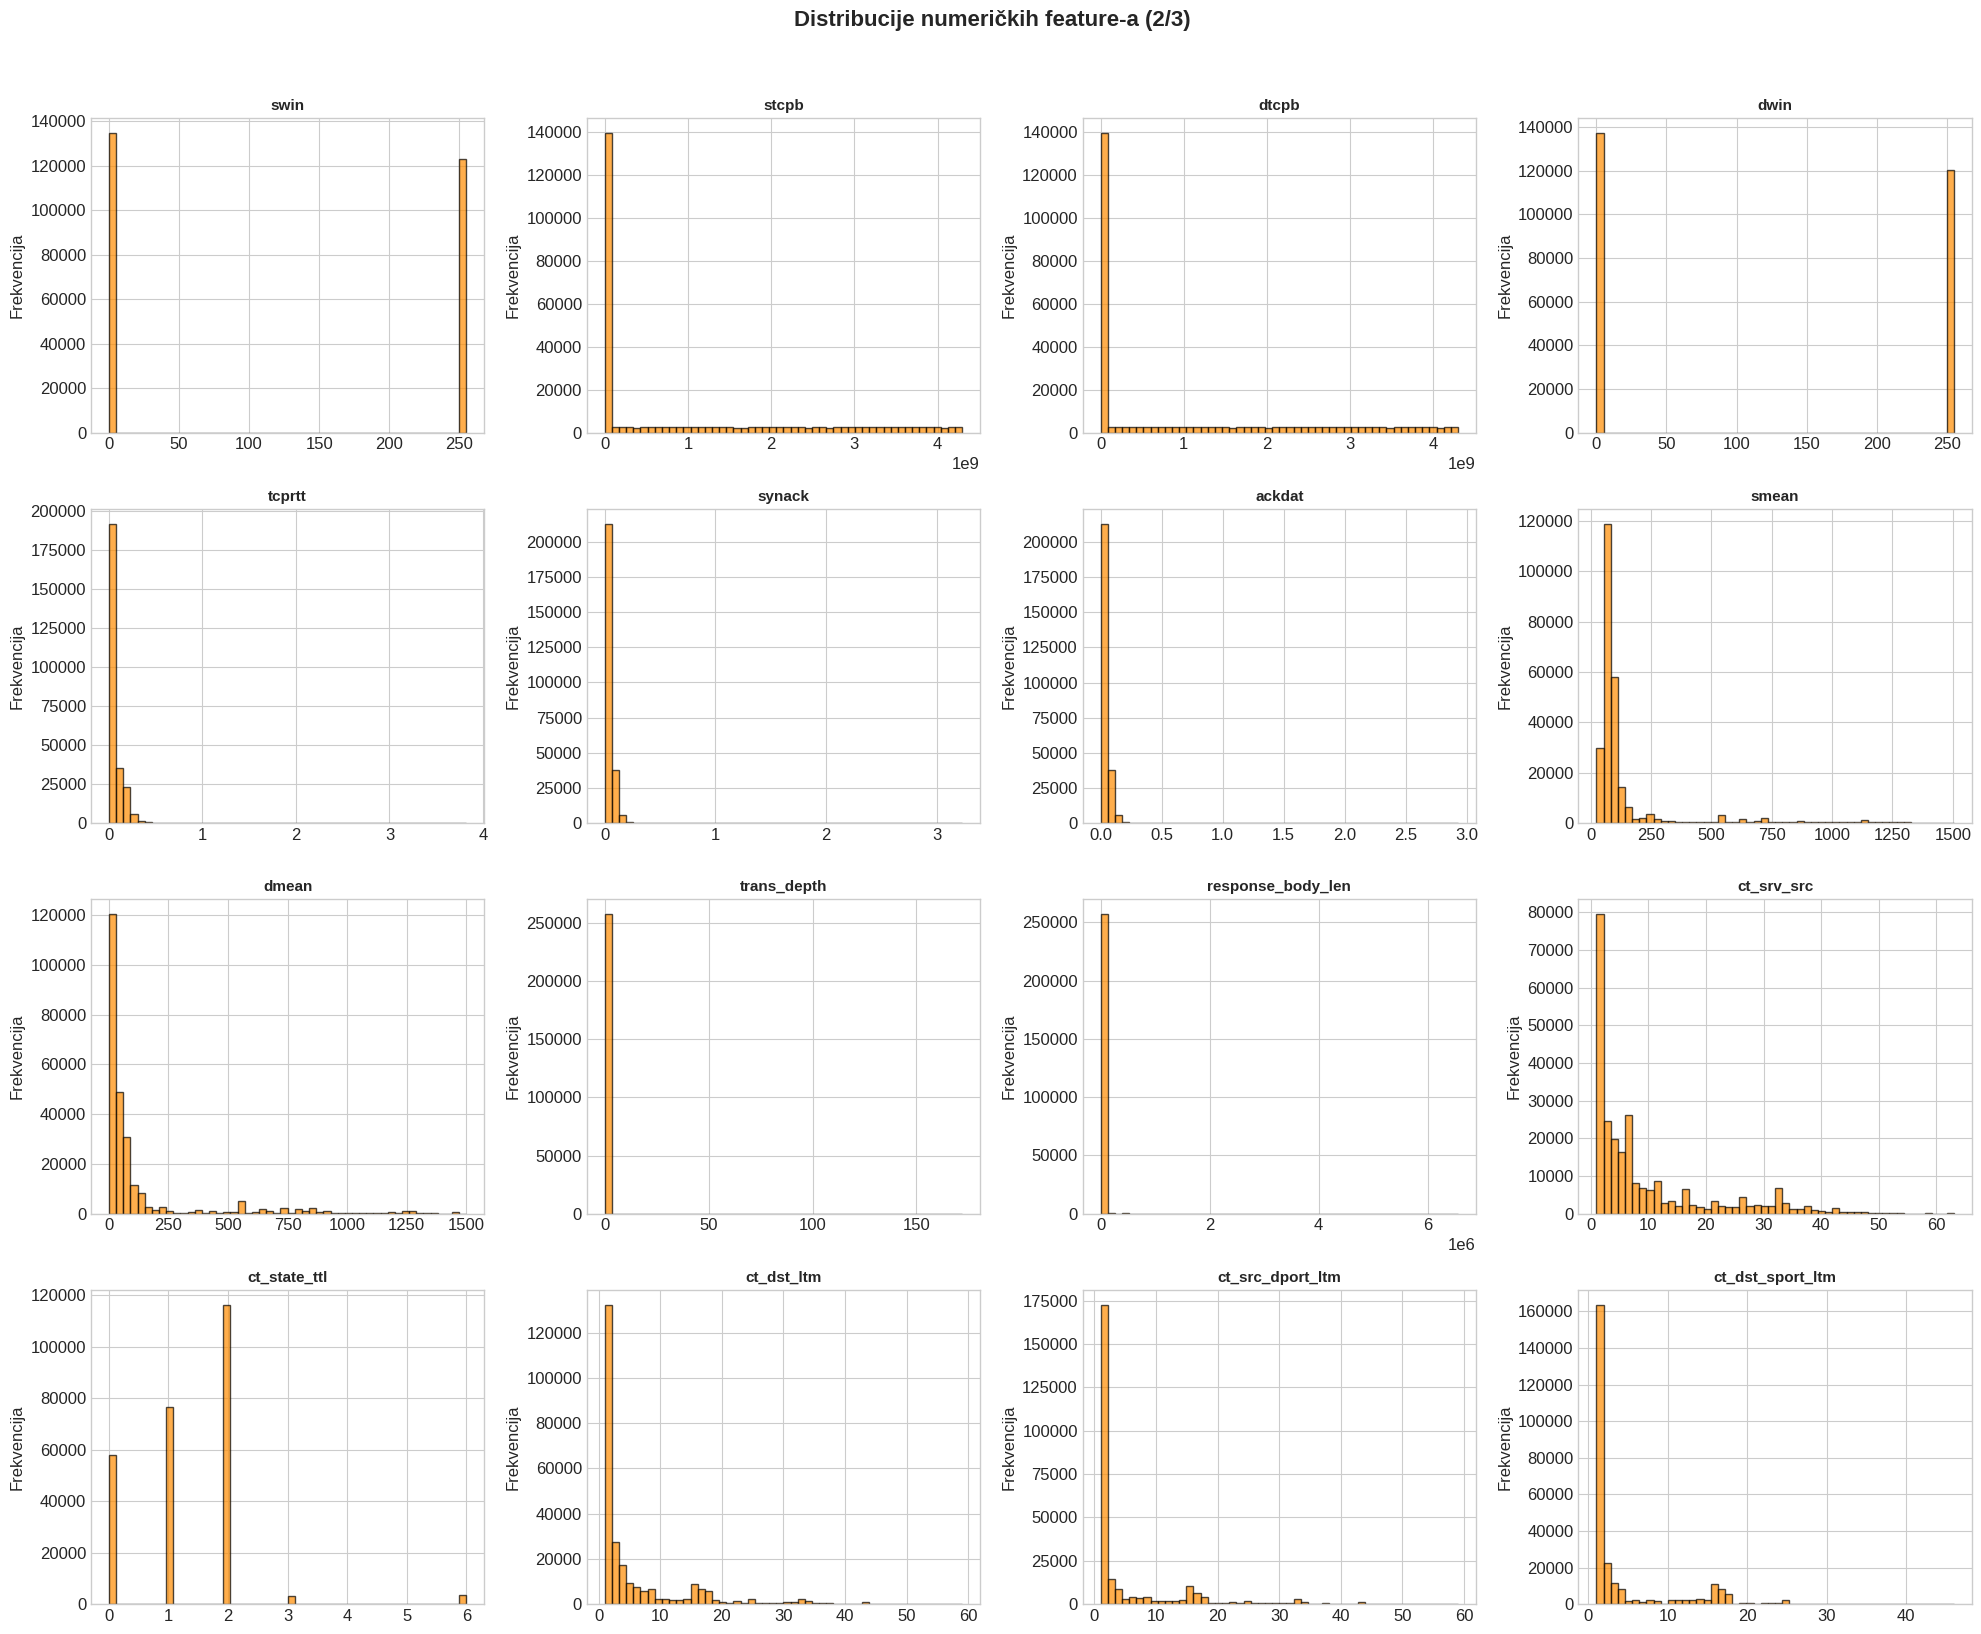

In [27]:
# Histogrami za sljedećih 16 numeričkih feature-a
remaining = numeric_features[16:32]
if remaining:
    n_plots = len(remaining)
    n_rows = (n_plots + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows))
    axes = axes.flatten()

    for idx, col in enumerate(remaining):
        ax = axes[idx]
        df[col].hist(bins=50, ax=ax, color='darkorange', edgecolor='black', alpha=0.7)
        ax.set_title(col, fontsize=11, fontweight='bold')
        ax.set_ylabel('Frekvencija')

    # Sakrij prazne subplot-ove
    for idx in range(n_plots, len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle('Distribucije numeričkih feature-a (2/3)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

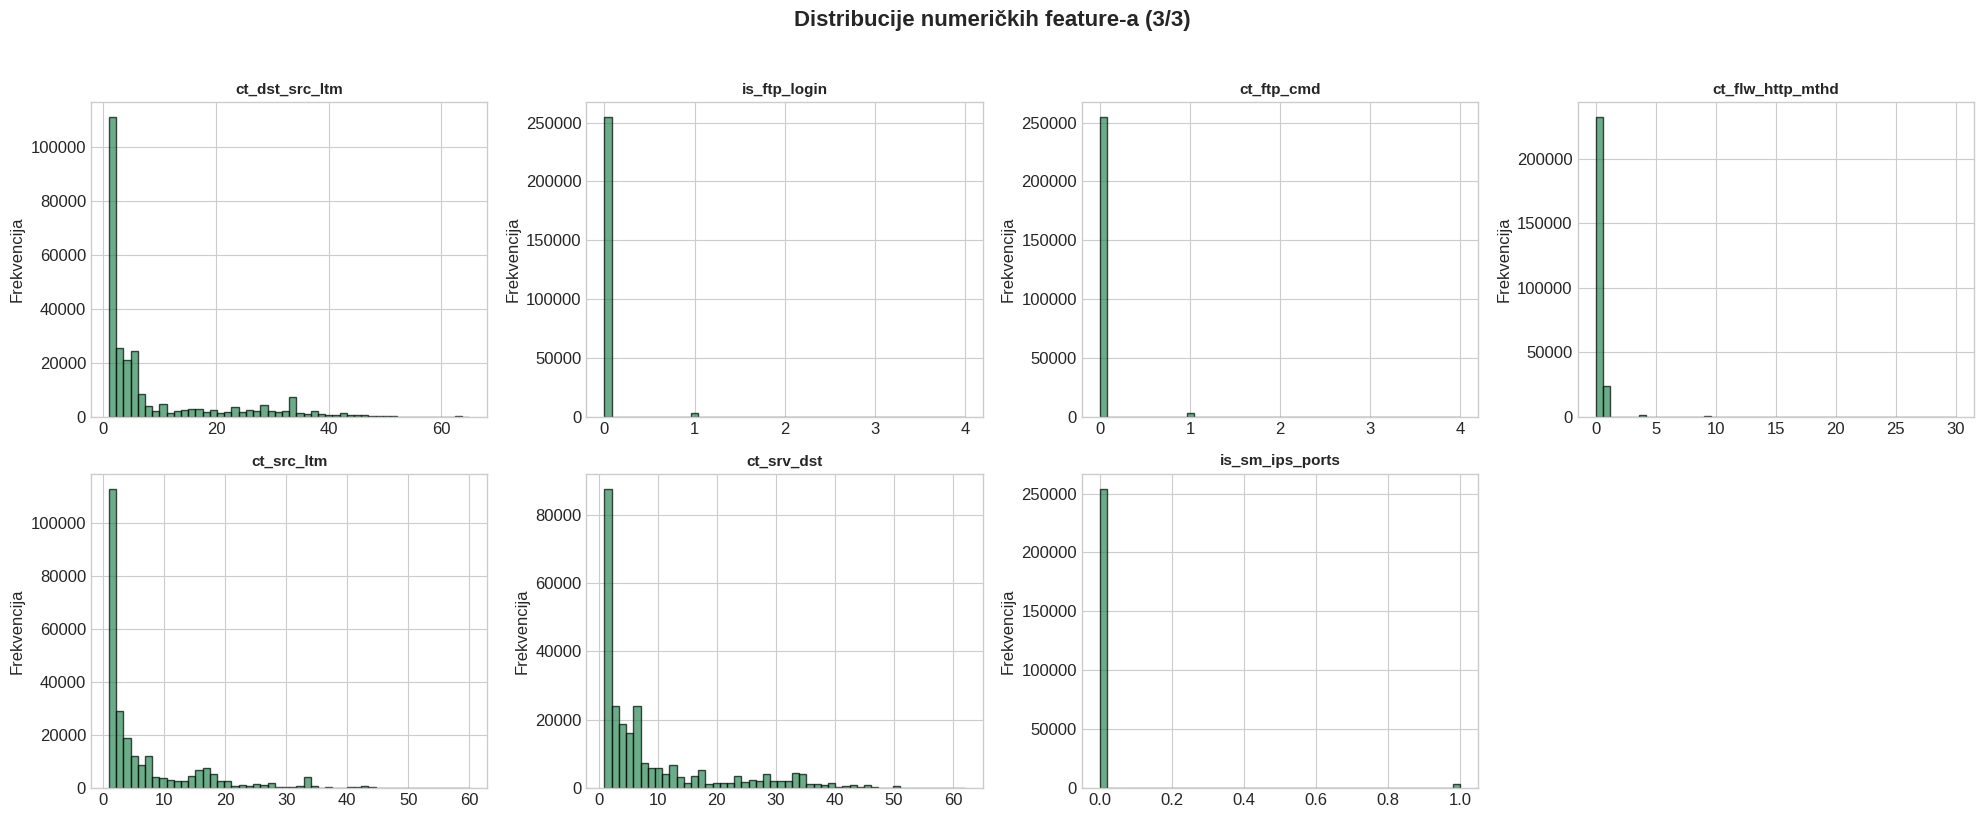

In [28]:
# Preostali numerički feature-i
remaining2 = numeric_features[32:]
if remaining2:
    n_plots = len(remaining2)
    n_rows = (n_plots + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows))
    if n_rows == 1:
        axes = [axes] if n_plots == 1 else axes
    axes = np.array(axes).flatten()

    for idx, col in enumerate(remaining2):
        ax = axes[idx]
        df[col].hist(bins=50, ax=ax, color='seagreen', edgecolor='black', alpha=0.7)
        ax.set_title(col, fontsize=11, fontweight='bold')
        ax.set_ylabel('Frekvencija')

    for idx in range(n_plots, len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle('Distribucije numeričkih feature-a (3/3)', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

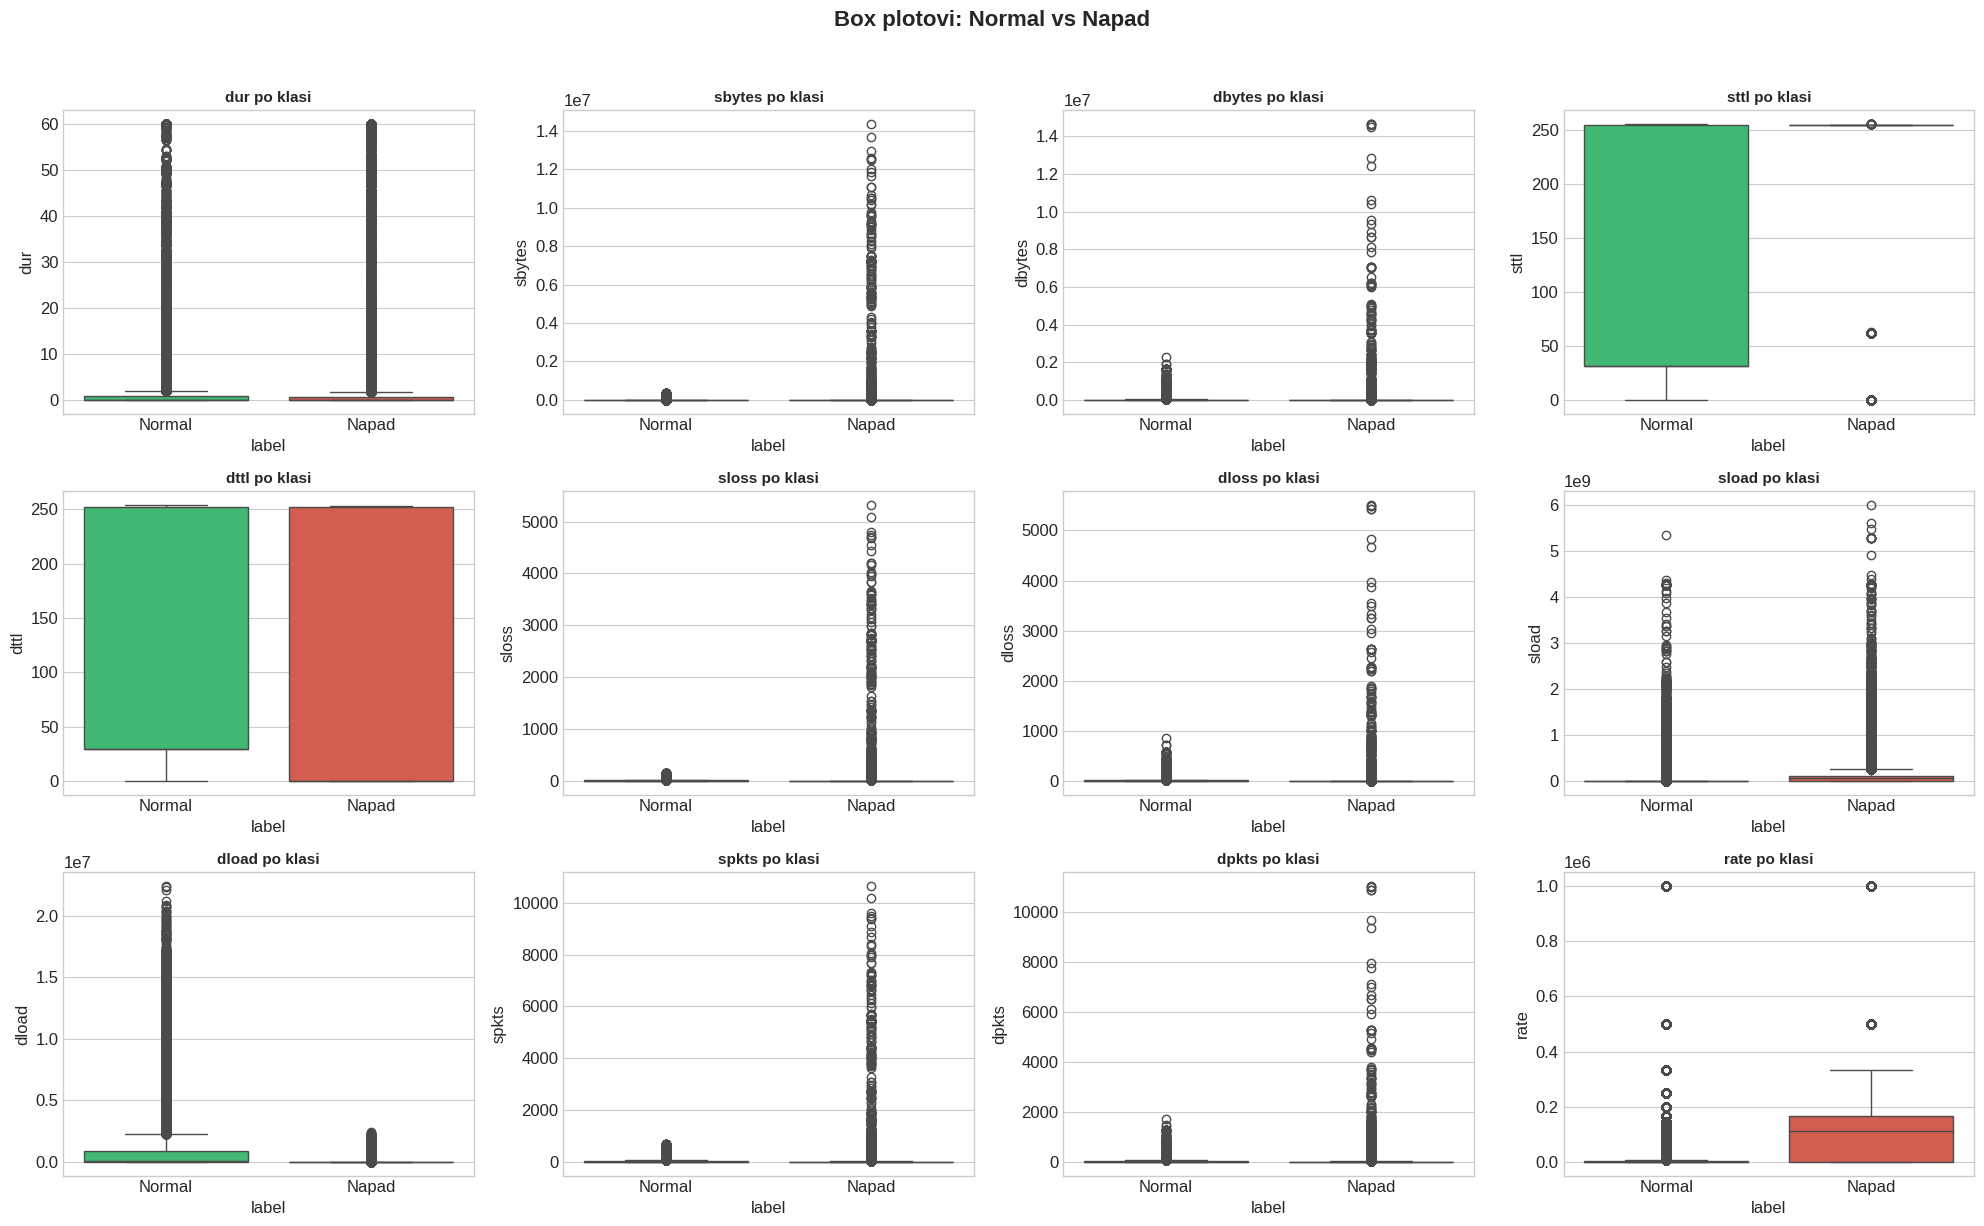

In [29]:
# Box plot-ovi za detekciju outlier-a (odabrani feature-i)
selected_features = ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss',
                     'sload', 'dload', 'spkts', 'dpkts', 'rate']
# Filtriraj samo postojeće kolone
selected_features = [f for f in selected_features if f in df.columns]

if selected_features:
    n_plots = len(selected_features)
    n_rows = (n_plots + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4 * n_rows))
    axes = np.array(axes).flatten()

    for idx, col in enumerate(selected_features):
        sns.boxplot(data=df, y=col, x='label', ax=axes[idx], palette=colors)
        axes[idx].set_title(f'{col} po klasi', fontsize=11, fontweight='bold')
        axes[idx].set_xticklabels(['Normal', 'Napad'])

    for idx in range(n_plots, len(axes)):
        axes[idx].set_visible(False)

    plt.suptitle('Box plotovi: Normal vs Napad', fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

In [30]:
# Detekcija outlier-a korištenjem IQR metode
print('=== Analiza outlier-a (IQR metoda) ===')
outlier_info = []

for col in numeric_features:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_pct = (outliers / len(df)) * 100
    outlier_info.append({
        'Feature': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Outlieri': outliers,
        'Procenat (%)': round(outlier_pct, 2)
    })

outlier_df = pd.DataFrame(outlier_info).sort_values('Procenat (%)', ascending=False)
display(outlier_df.head(20))

=== Analiza outlier-a (IQR metoda) ===


,Feature,Q1,Q3,IQR,Outlieri,Procenat (%)
9,dload,0.0000,22105.3848,22105.3848,57556,22.3400
30,ct_src_dport_ltm,1.0000,4.0000,3.0000,49014,19.0200
31,ct_dst_sport_ltm,1.0000,3.0000,2.0000,48244,18.7200
32,ct_dst_src_ltm,1.0000,8.0000,7.0000,43419,16.8500
29,ct_dst_ltm,1.0000,6.0000,5.0000,42388,16.4500
4,dbytes,0.0000,1064.0000,1064.0000,40024,15.5300
11,dloss,0.0000,2.0000,2.0000,39660,15.3900
1,spkts,2.0000,12.0000,10.0000,34871,13.5300
37,ct_srv_dst,2.0000,11.0000,9.0000,34048,13.2100
24,dmean,0.0000,89.0000,89.0000,33189,12.8800


Na histogramima se vidi da je većina vrijednosti skupljena blizu nule, uz mali broj ogromnih vrijednosti. Zato provjeravamo koeficijent asimetrije (skewness) i kako log transformacija utiče na distribucije.

=== Top 15 najasimetričnijih feature-a ===


,0
trans_depth,173.1600
response_body_len,78.4800
sbytes,47.9200
sloss,47.1200
dloss,46.0900
dbytes,44.3400
spkts,42.5200
dpkts,41.1900
djit,37.5000
dinpkt,26.9700



Feature-i sa |skewness| > 1: 35 od 39


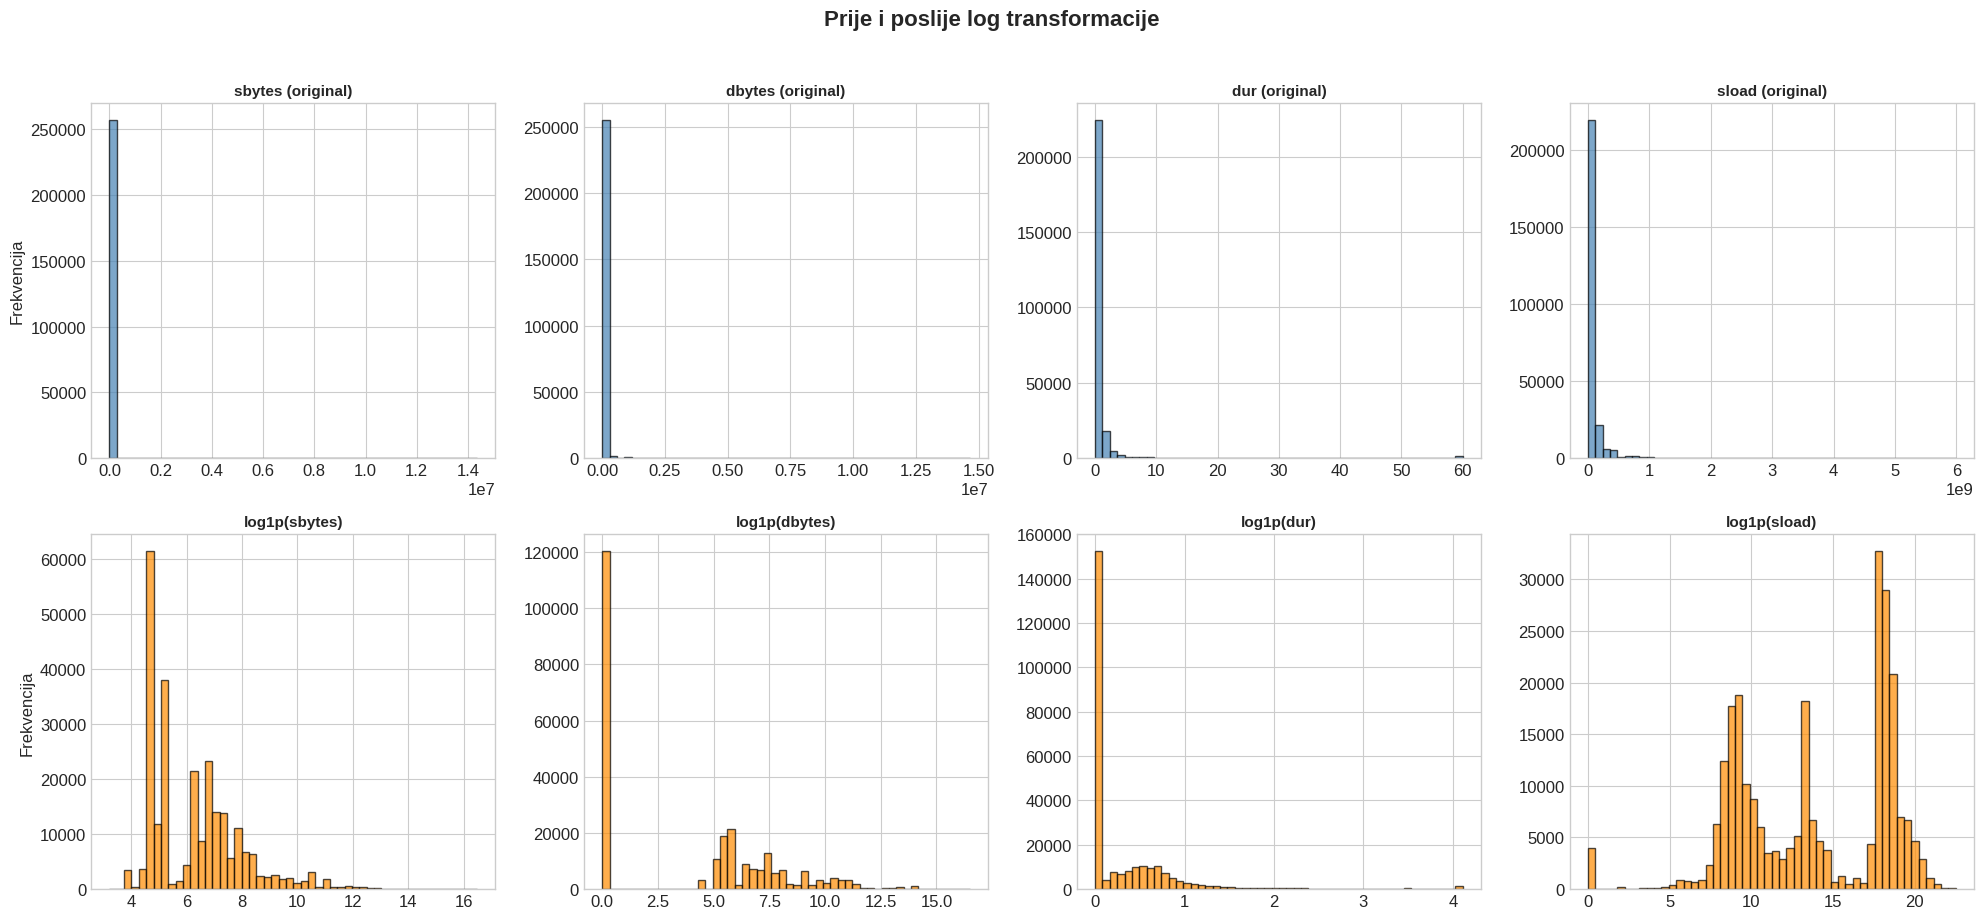

,Prije,Poslije log1p
trans_depth,173.1600,2.9500
response_body_len,78.4800,4.1600
sbytes,47.9200,1.1500
sloss,47.1200,1.3400
dloss,46.0900,1.8000
dbytes,44.3400,0.3300
spkts,42.5200,1.1000
dpkts,41.1900,0.7600
djit,37.5000,0.8000
dinpkt,26.9700,0.8500


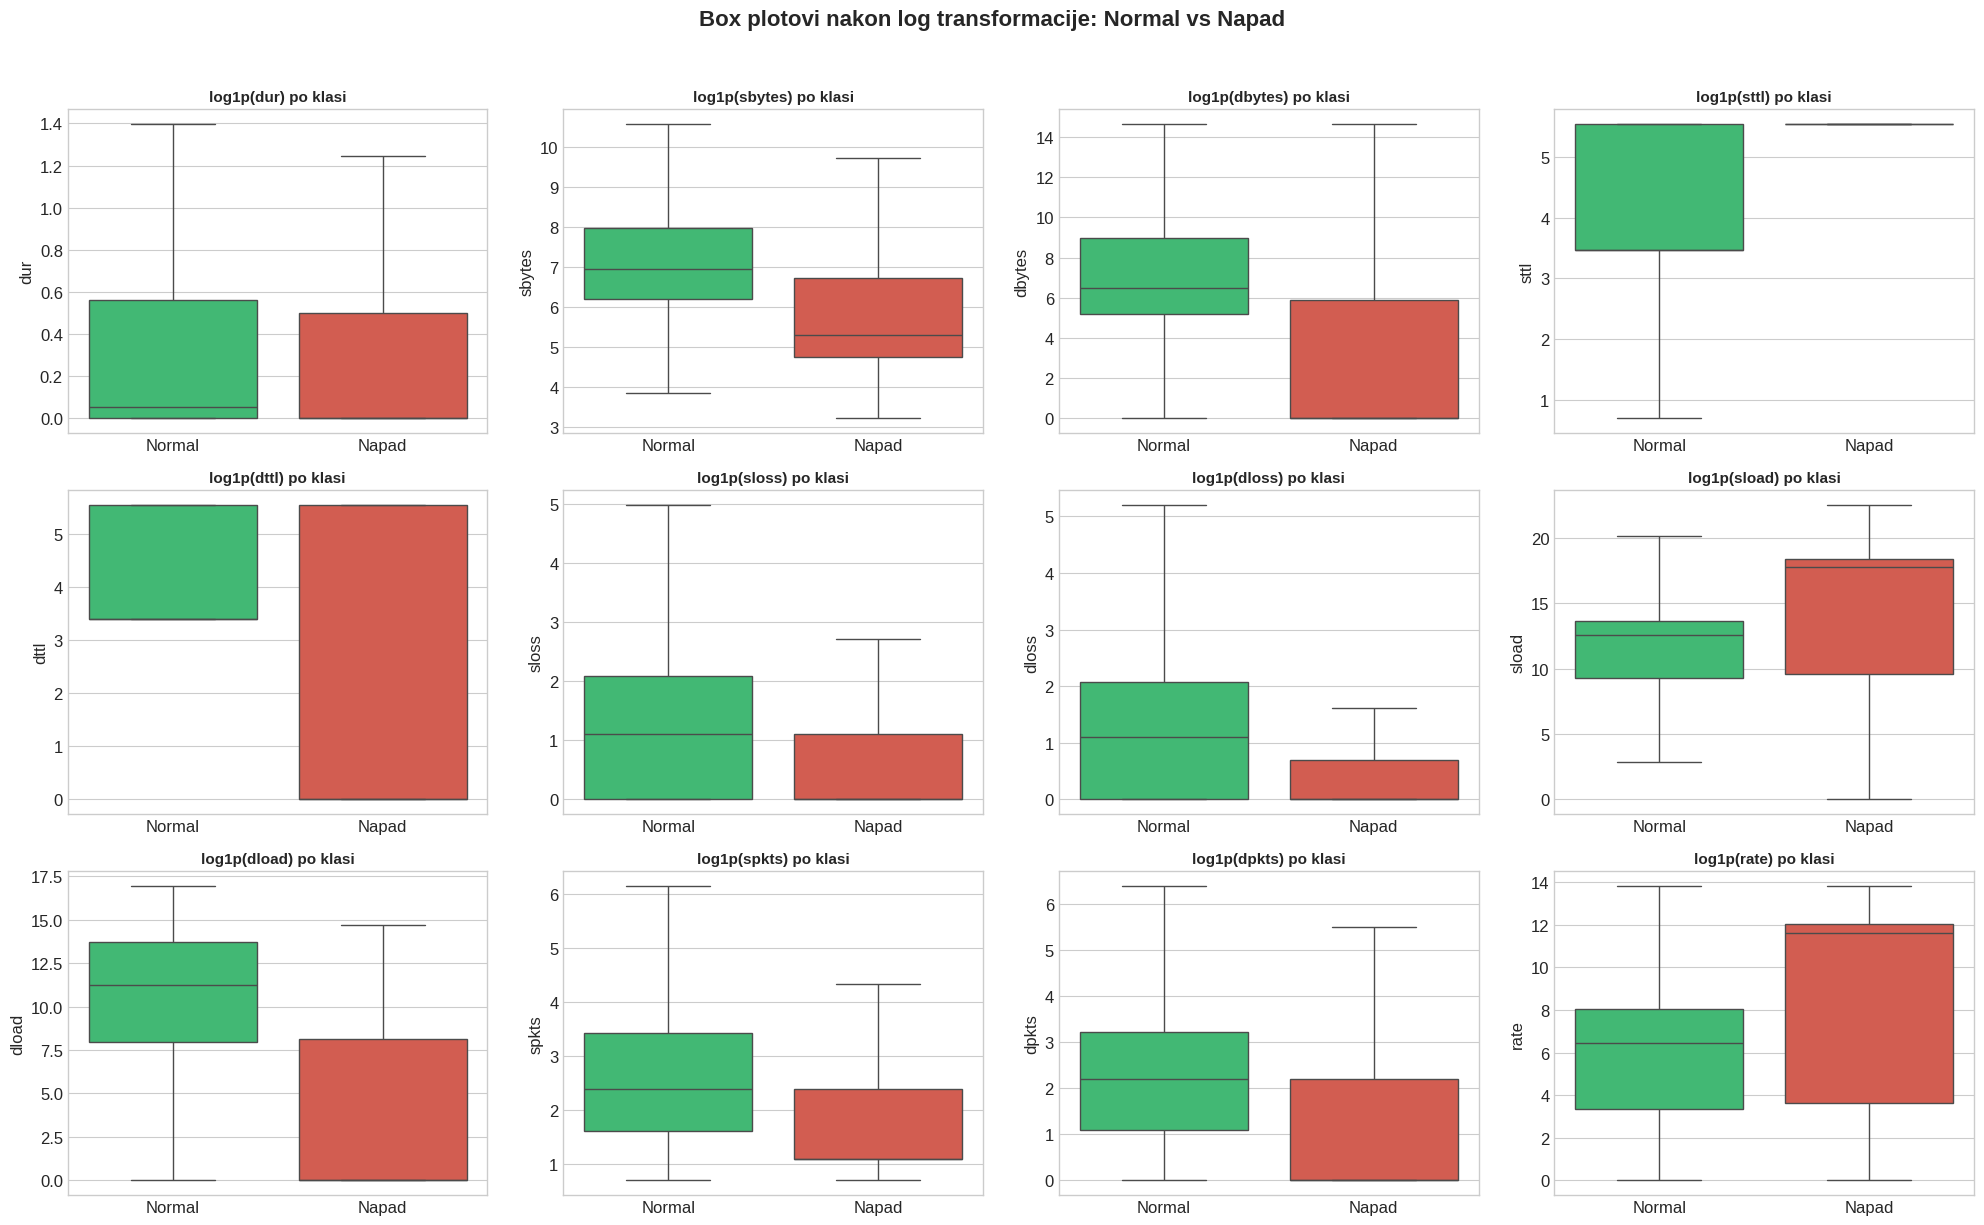

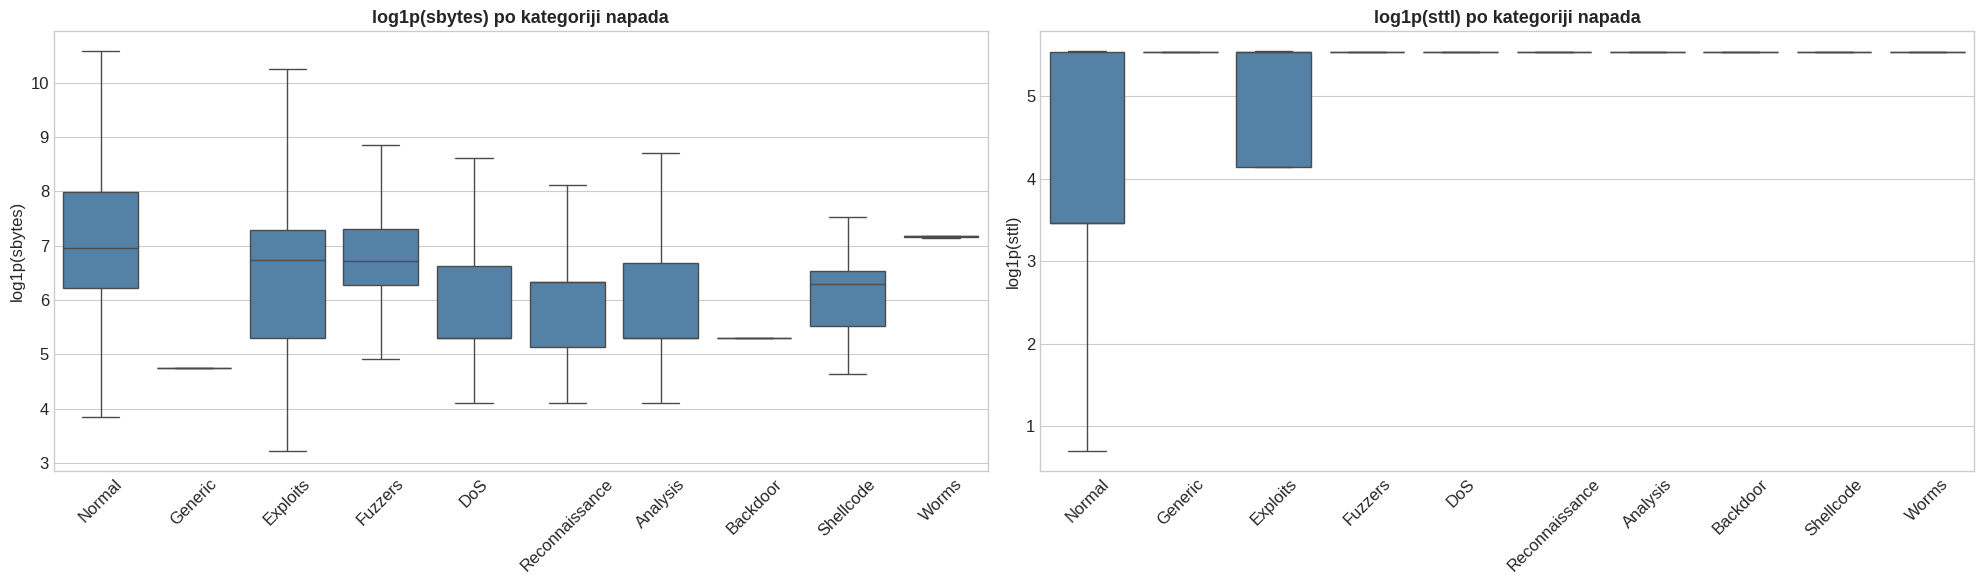

In [43]:
# Koeficijent asimetrije (skewness) za sve numeričke feature-e
skewness = df[numeric_features].skew().sort_values(key=abs, ascending=False)

print('=== Top 15 najasimetričnijih feature-a ===')
display(skewness.head(15).round(2))

skewed_features = skewness[skewness.abs() > 1].index.tolist()
print(f'\nFeature-i sa |skewness| > 1: {len(skewed_features)} od {len(numeric_features)}')

# Poređenje distribucija prije i poslije log1p transformacije
compare_cols = ['sbytes', 'dbytes', 'dur', 'sload']

fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for idx, col in enumerate(compare_cols):
    axes[0, idx].hist(df[col], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0, idx].set_title(f'{col} (original)', fontsize=11, fontweight='bold')

    axes[1, idx].hist(np.log1p(df[col]), bins=50, color='darkorange', edgecolor='black', alpha=0.7)
    axes[1, idx].set_title(f'log1p({col})', fontsize=11, fontweight='bold')

axes[0, 0].set_ylabel('Frekvencija')
axes[1, 0].set_ylabel('Frekvencija')
plt.suptitle('Prije i poslije log transformacije', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Tabela: skewness prije i poslije
skew_after = np.log1p(df[skewed_features]).skew()
skew_compare = pd.DataFrame({
    'Prije': skewness[skewed_features],
    'Poslije log1p': skew_after
}).round(2)
display(skew_compare.head(15))

# Box plotovi na log skali: Normal vs Napad
colors = ['#2ecc71', '#e74c3c']
selected_features = ['dur', 'sbytes', 'dbytes', 'sttl', 'dttl', 'sloss', 'dloss',
                     'sload', 'dload', 'spkts', 'dpkts', 'rate']

plot_df = df[selected_features + ['label']].copy()
plot_df[selected_features] = np.log1p(plot_df[selected_features])

fig, axes = plt.subplots(3, 4, figsize=(20, 12))
axes = axes.flatten()
for idx, col in enumerate(selected_features):
    sns.boxplot(data=plot_df, x='label', y=col, hue='label', palette=colors,
                legend=False, ax=axes[idx], showfliers=False)
    axes[idx].set_title(f'log1p({col}) po klasi', fontsize=11, fontweight='bold')
    axes[idx].set_xticks([0, 1])
    axes[idx].set_xticklabels(['Normal', 'Napad'])
    axes[idx].set_xlabel('')

plt.suptitle('Box plotovi nakon log transformacije: Normal vs Napad', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Kako se sbytes i sttl razlikuju po kategorijama napada
order = df['attack_cat'].str.strip().value_counts().index

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, col in zip(axes, ['sbytes', 'sttl']):
    sns.boxplot(x=df['attack_cat'].str.strip(), y=np.log1p(df[col]), order=order, ax=ax,
                color='steelblue', showfliers=False)
    ax.set_title(f'log1p({col}) po kategoriji napada', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel(f'log1p({col})')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


In [31]:
# Kategoričke kolone
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols = [c for c in cat_cols if c != 'source']  # Isključi pomoćnu kolonu

print(f'Kategorički feature-i ({len(cat_cols)}):')
for col in cat_cols:
    print(f'  {col}: {df[col].nunique()} jedinstvenih vrijednosti')

Kategorički feature-i (4):
  proto: 133 jedinstvenih vrijednosti
  service: 13 jedinstvenih vrijednosti
  state: 11 jedinstvenih vrijednosti
  attack_cat: 10 jedinstvenih vrijednosti


=== Top 15 protokola ===


,count
proto,
tcp,123041
udp,92701
unas,15599
arp,3846
ospf,3271
sctp,1474
any,396
gre,313
rsvp,264


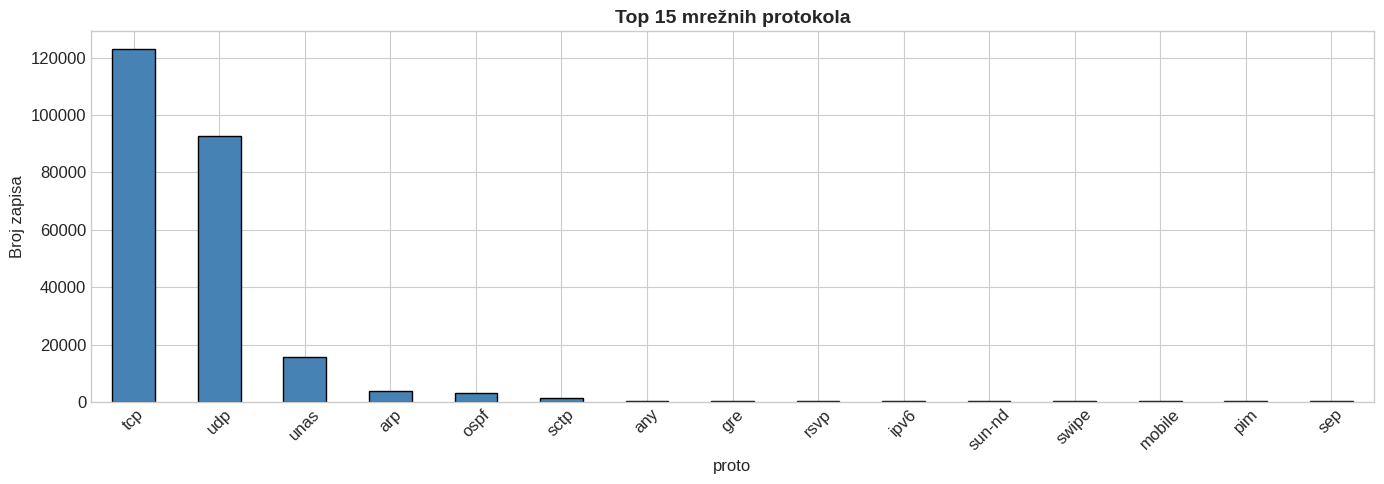

In [32]:
# Analiza 'proto' kolone (protokol)
print('=== Top 15 protokola ===')
proto_counts = df['proto'].value_counts()
display(proto_counts.head(15))

fig, ax = plt.subplots(figsize=(14, 5))
proto_counts.head(15).plot(kind='bar', ax=ax, color='steelblue', edgecolor='black')
ax.set_title('Top 15 mrežnih protokola', fontsize=14, fontweight='bold')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

=== Distribucija servisa ===


,count
service,
-,141321
dns,68661
http,27011
smtp,6909
ftp-data,5391
ftp,4980
pop3,1528
ssh,1506
dhcp,120


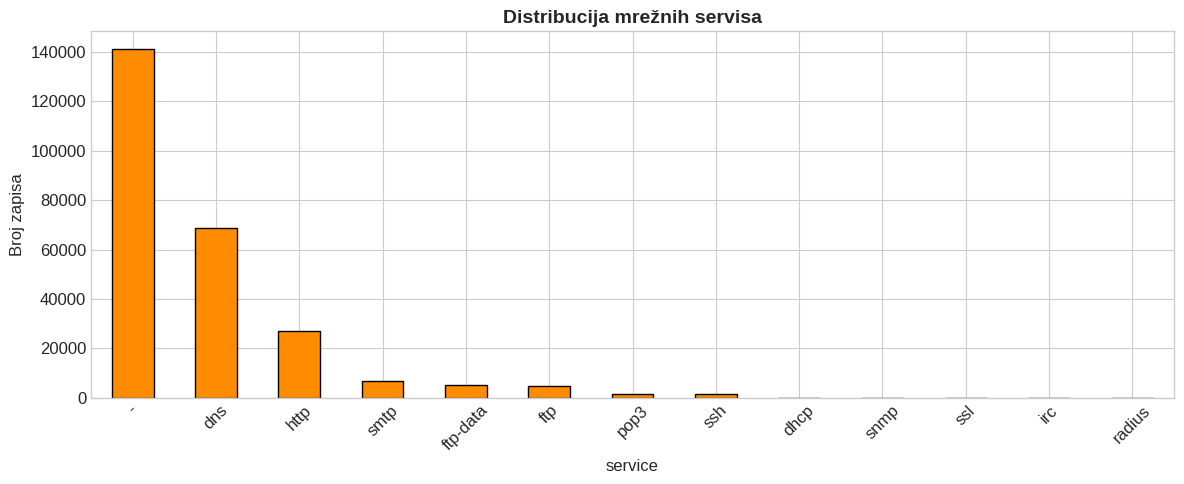

In [33]:
# Analiza 'service' kolone
print('=== Distribucija servisa ===')
service_counts = df['service'].value_counts()
display(service_counts)

fig, ax = plt.subplots(figsize=(12, 5))
service_counts.plot(kind='bar', ax=ax, color='darkorange', edgecolor='black')
ax.set_title('Distribucija mrežnih servisa', fontsize=14, fontweight='bold')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

=== Distribucija stanja konekcije ===


,count
state,
FIN,117164
INT,116438
CON,20134
REQ,3833
RST,84
ECO,12
ACC,4
PAR,1
URN,1


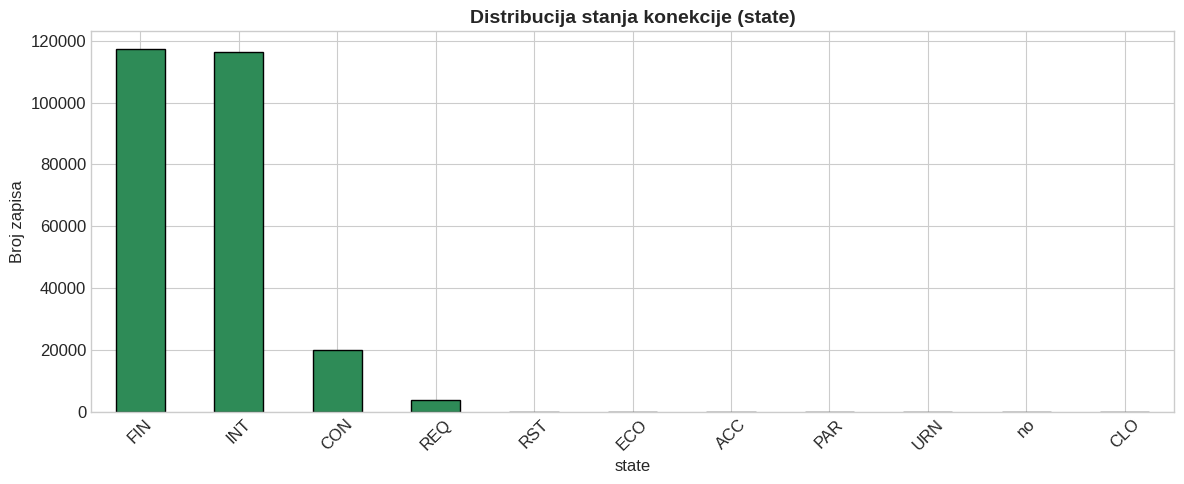

In [34]:
# Analiza 'state' kolone
print('=== Distribucija stanja konekcije ===')
state_counts = df['state'].value_counts()
display(state_counts)

fig, ax = plt.subplots(figsize=(12, 5))
state_counts.plot(kind='bar', ax=ax, color='seagreen', edgecolor='black')
ax.set_title('Distribucija stanja konekcije (state)', fontsize=14, fontweight='bold')
ax.set_ylabel('Broj zapisa')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

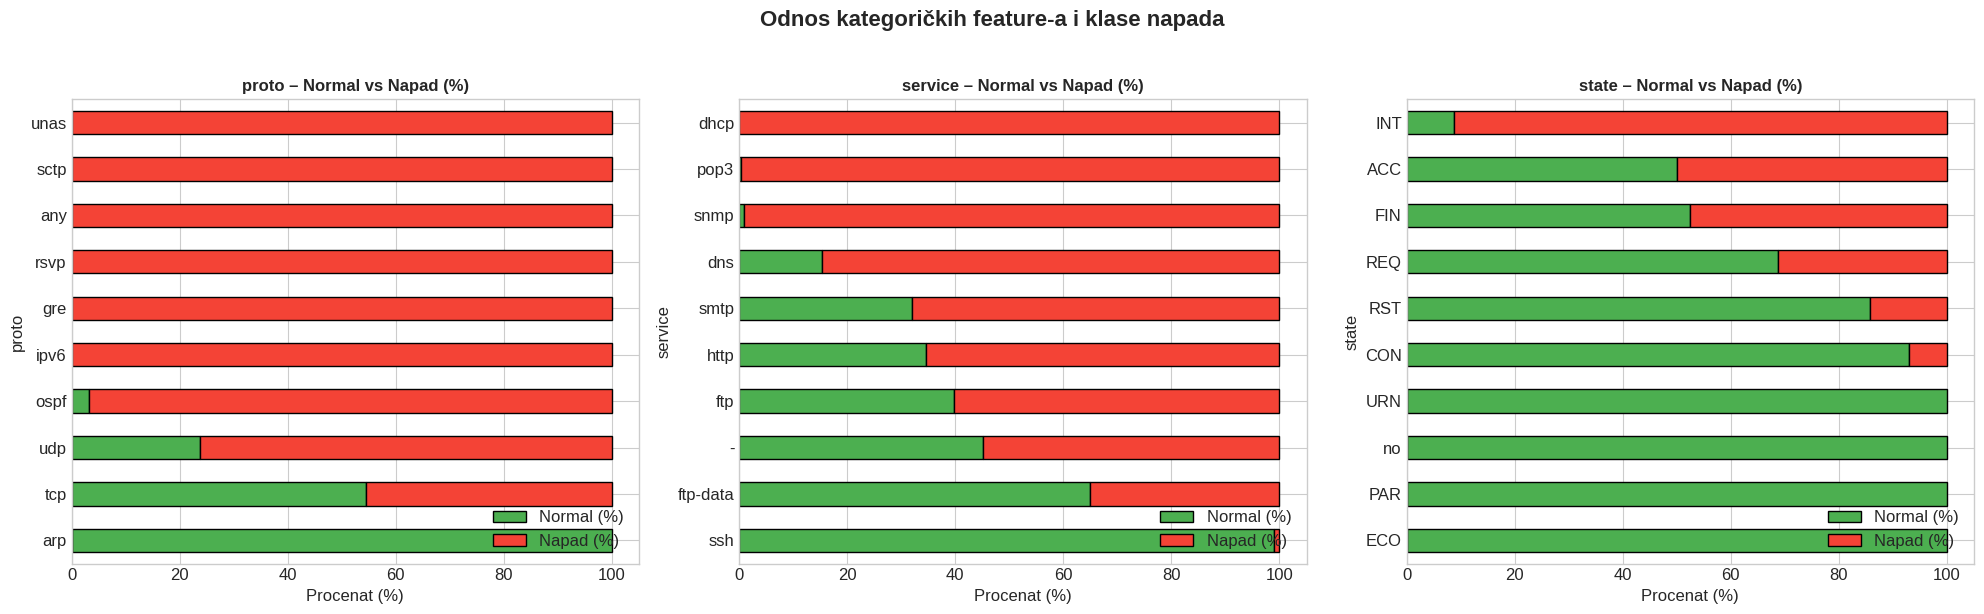

In [35]:
# Odnos kategoričkih feature-a i napada
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

colors = ['#4CAF50', '#F44336']

for idx, col in enumerate(['proto', 'service', 'state']):
    top_vals = df[col].value_counts().head(10).index
    subset = df[df[col].isin(top_vals)]
    ct = pd.crosstab(subset[col], subset['label'], normalize='index') * 100
    ct.columns = ['Normal (%)', 'Napad (%)']
    ct.sort_values('Napad (%)', ascending=True).plot(
        kind='barh', stacked=True, ax=axes[idx], color=colors, edgecolor='black'
    )
    axes[idx].set_title(f'{col} – Normal vs Napad (%)', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Procenat (%)')
    axes[idx].legend(loc='lower right')

plt.suptitle('Odnos kategoričkih feature-a i klase napada', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

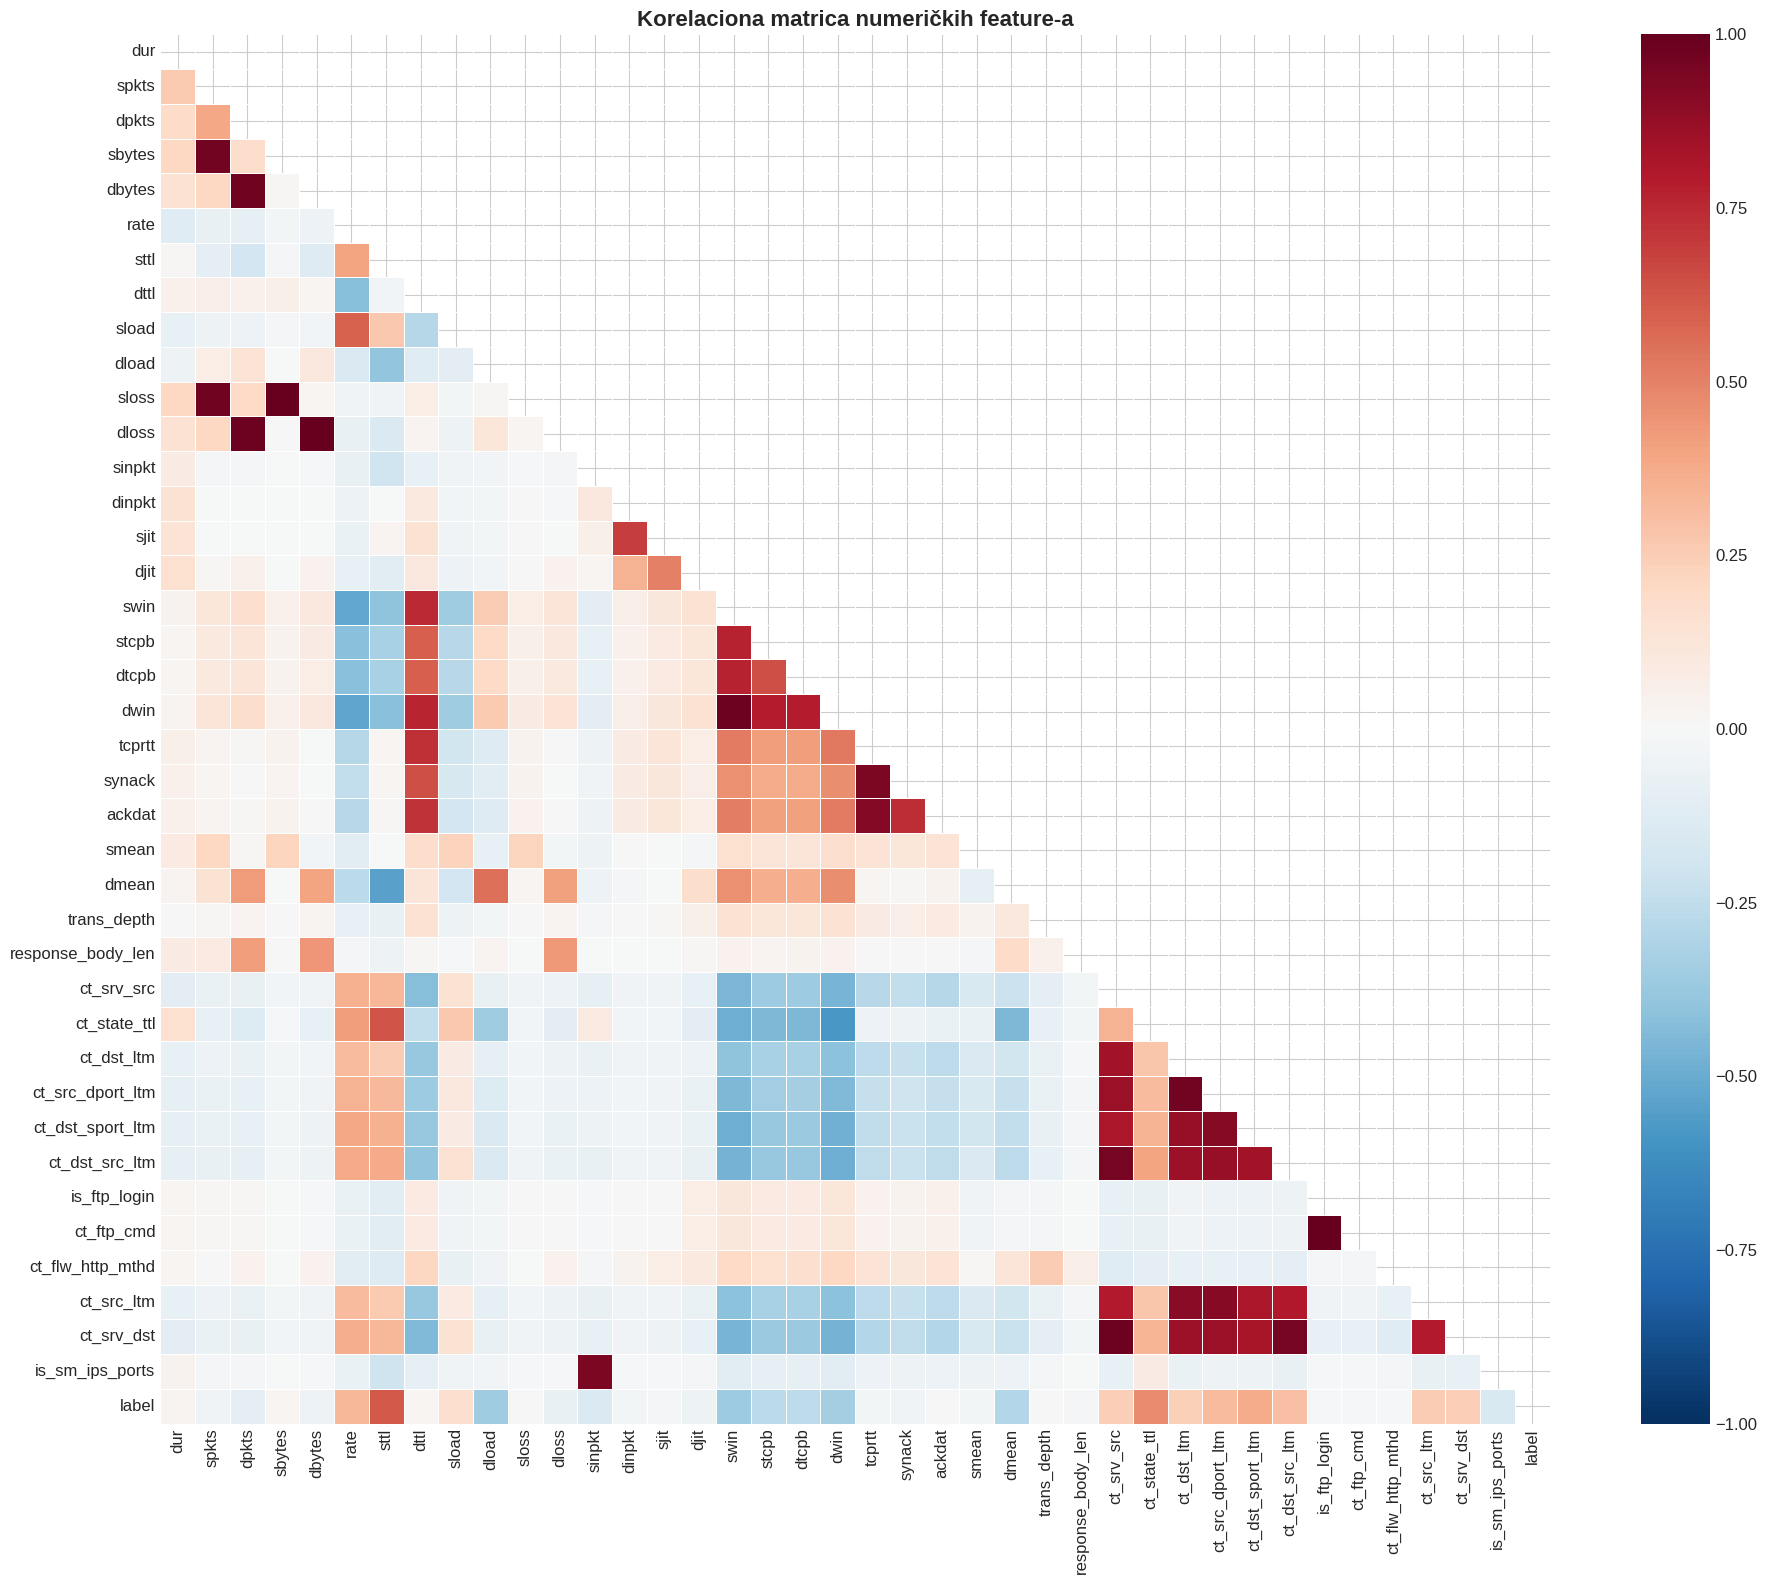

In [36]:
# Korelaciona matrica
corr_matrix = df[numeric_features + ['label']].corr()

# Heatmapa
fig, ax = plt.subplots(figsize=(20, 16))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=False, cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, vmin=-1, vmax=1)
ax.set_title('Korelaciona matrica numeričkih feature-a', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

=== Top 20 feature-a po korelaciji sa label-om ===


,label
sttl,0.6241
ct_state_ttl,0.4766
ct_dst_sport_ltm,0.3717
swin,-0.3649
dload,-0.3522
dwin,-0.3392
rate,0.3359
ct_src_dport_ltm,0.3185
ct_dst_src_ltm,0.2996
dmean,-0.2952


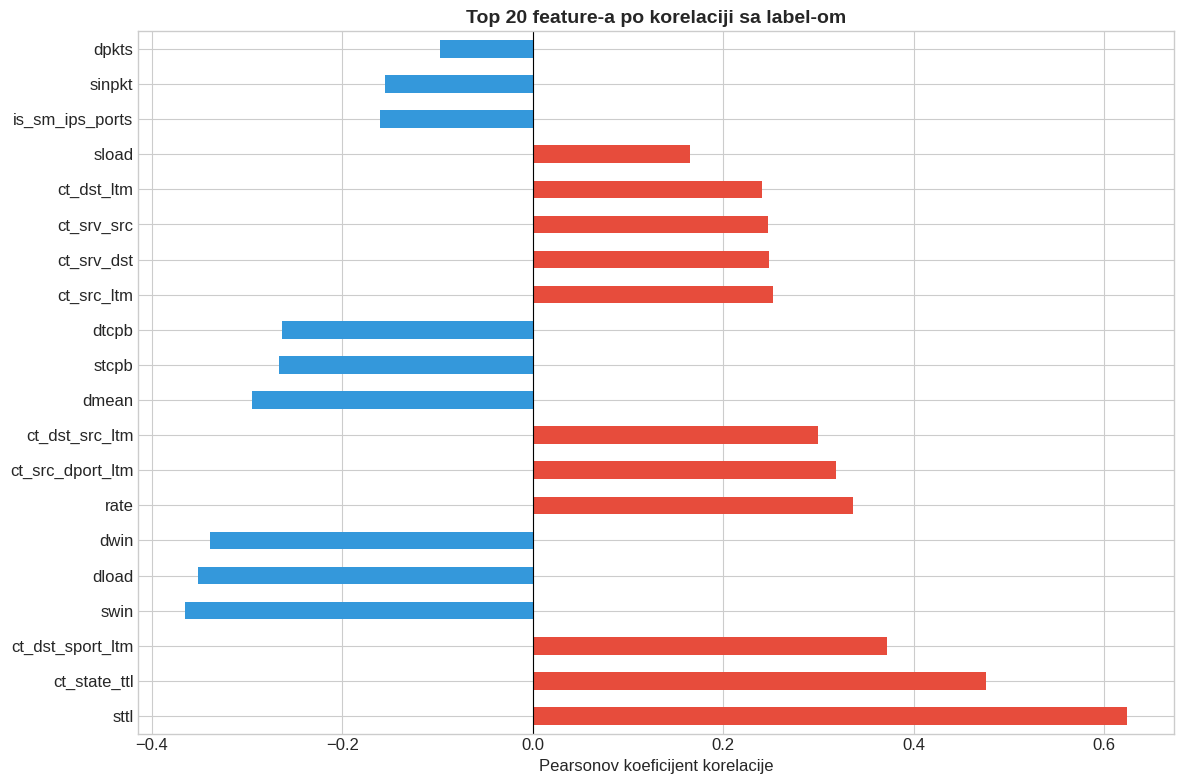

In [37]:
# Korelacija sa ciljnom varijablom (label)
label_corr = corr_matrix['label'].drop('label').sort_values(key=abs, ascending=False)

print('=== Top 20 feature-a po korelaciji sa label-om ===')
display(label_corr.head(20))

fig, ax = plt.subplots(figsize=(12, 8))
label_corr.head(20).plot(kind='barh', ax=ax, color=label_corr.head(20).apply(
    lambda x: '#e74c3c' if x > 0 else '#3498db'
))
ax.set_title('Top 20 feature-a po korelaciji sa label-om', fontsize=14, fontweight='bold')
ax.set_xlabel('Pearsonov koeficijent korelacije')
ax.axvline(x=0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

In [38]:
# Visoko korelisani parovi feature-a (potencijalni kandidati za uklanjanje)
print('=== Visoko korelisani parovi feature-a (|r| > 0.85) ===')
high_corr_pairs = []

for i in range(len(corr_matrix.columns)):
    for j in range(i + 1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.85:
            high_corr_pairs.append({
                'Feature 1': corr_matrix.columns[i],
                'Feature 2': corr_matrix.columns[j],
                'Korelacija': round(corr_matrix.iloc[i, j], 4)
            })

high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Korelacija', key=abs, ascending=False)
display(high_corr_df)
print(f'\nUkupno visoko korelisanih parova: {len(high_corr_df)}')

=== Visoko korelisani parovi feature-a (|r| > 0.85) ===


,Feature 1,Feature 2,Korelacija
23,is_ftp_login,ct_ftp_cmd,0.9989
5,dbytes,dloss,0.9967
4,sbytes,sloss,0.9958
7,swin,dwin,0.9805
3,dpkts,dloss,0.9796
12,ct_srv_src,ct_srv_dst,0.9795
2,dpkts,dbytes,0.9734
1,spkts,sloss,0.9719
0,spkts,sbytes,0.9644
13,ct_dst_ltm,ct_src_dport_ltm,0.9615



Ukupno visoko korelisanih parova: 24
